# Face Recognition on LFW: From Classical CV to Deep Learning

**Task:** supervised multi-class classification, `f(X) → Y`
- X: face image tensor of shape (H, W, 3)
- Y: identity of the person

**Roadmap**
1. Load data and inspect tensors
2. Preprocessing and classical OpenCV filters
3. Baseline CNN
4. Transfer learning (pretrained CNN)
5. Vision Transformers (concept)
6. Comparison: accuracy, generalization, compute cost

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import fetch_lfw_people

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
OpenCV: 5.0.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Loading the LFW dataset

- `color=True` keeps the 3 RGB channels. sklearn returns grayscale by default.
- `min_faces_per_person=20` keeps only identities with at least 20 images.
  People with 1 or 2 images can't be split across train/validation/test, and the
  model would have almost nothing to learn from for those classes.
- `resize=1.0` keeps the full cropped face (125x94). We can downsample later,
  but we can't recover detail we threw away.

In [24]:
MIN_FACES = 20

lfw = fetch_lfw_people(min_faces_per_person=MIN_FACES, resize=1.0, color=True)

X = lfw.images          # (N, H, W, C)
y = lfw.target          # integer identity labels
class_names = lfw.target_names

print("Downloaded and cached.")

Downloaded and cached.


In [25]:
n_samples, h, w, c = X.shape
n_classes = len(class_names)

print(f"Single image shape : {X[0].shape}  -> (Height, Width, Channels)")
print(f"Batch shape (all)  : {X.shape}  -> (N, Height, Width, Channels)")
print(f"dtype              : {X.dtype}")
print(f"Pixel range        : {X.min():.3f} to {X.max():.3f}")
print(f"Number of images   : {n_samples}")
print(f"Number of identities: {n_classes}")
print(f"Memory             : {X.nbytes / 1e6:.0f} MB")
print(f"Labels shape       : {y.shape}, sample labels: {y[:5]} -> {class_names[y[:5]]}")

Single image shape : (125, 94, 3)  -> (Height, Width, Channels)
Batch shape (all)  : (3023, 125, 94, 3)  -> (N, Height, Width, Channels)
dtype              : float32
Pixel range        : 0.000 to 1.000
Number of images   : 3023
Number of identities: 62
Memory             : 426 MB
Labels shape       : (3023,), sample labels: [61 25  9  5  1] -> ['Winona Ryder' 'Jean Chretien' 'Carlos Menem' 'Ariel Sharon'
 'Alvaro Uribe']


Top 10 identities:
  George W Bush              530
  Colin Powell               236
  Tony Blair                 144
  Donald Rumsfeld            121
  Gerhard Schroeder          109
  Ariel Sharon                77
  Hugo Chavez                 71
  Junichiro Koizumi           60
  Jean Chretien               55
  John Ashcroft               53

Smallest class: 20 images | Largest class: 530 images
Majority-class baseline accuracy: 17.5%


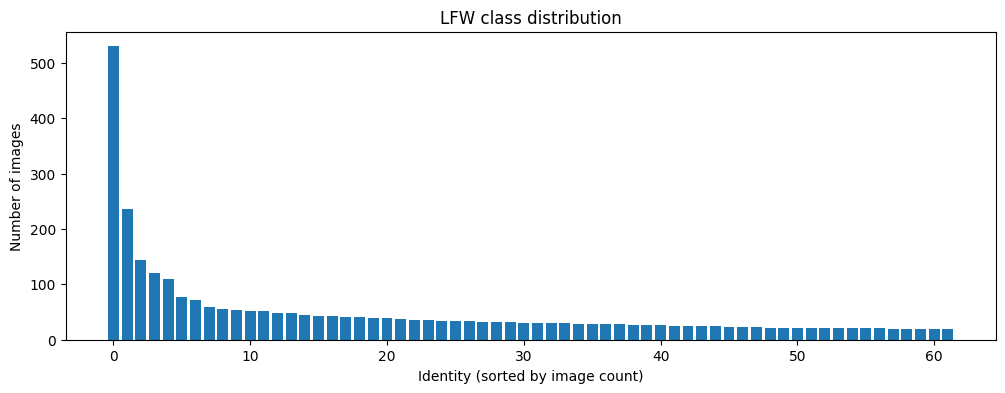

In [26]:
counts = np.bincount(y)
order = np.argsort(counts)[::-1]

print("Top 10 identities:")
for idx in order[:10]:
    print(f"  {class_names[idx]:25s} {counts[idx]:4d}")
print(f"\nSmallest class: {counts.min()} images | Largest class: {counts.max()} images")
print(f"Majority-class baseline accuracy: {counts.max() / n_samples:.1%}")

plt.figure(figsize=(12, 4))
plt.bar(range(n_classes), counts[order])
plt.xlabel("Identity (sorted by image count)")
plt.ylabel("Number of images")
plt.title("LFW class distribution")
plt.show()

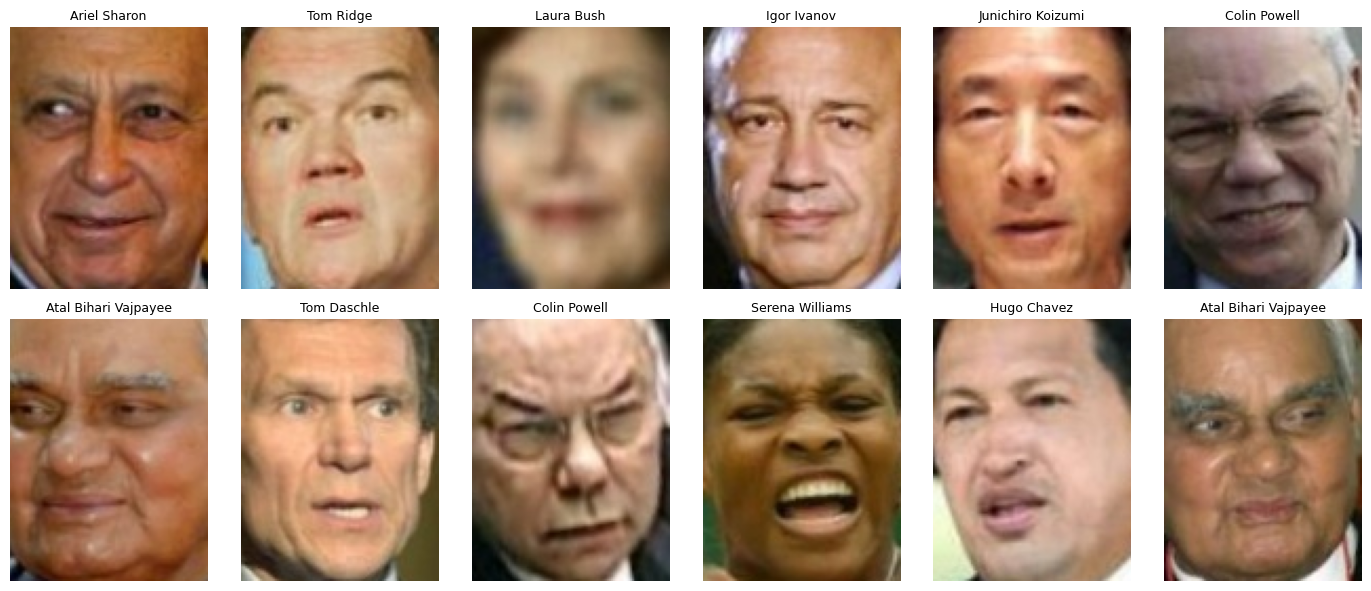

In [27]:
fig, axes = plt.subplots(2, 6, figsize=(14, 6))
rng = np.random.default_rng(SEED)
for ax, i in zip(axes.ravel(), rng.choice(n_samples, 12, replace=False)):
    ax.imshow(X[i])
    ax.set_title(class_names[y[i]], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Interpretation: what the data tells us

**Tensor representation**
- One image is a tensor of shape `(125, 94, 3)`: 125 pixels high, 94 wide, 3 RGB channels. The full dataset is a batch tensor of shape `(3023, 125, 94, 3)`, which matches the `(N, H, W, C)` layout that Keras convolution layers expect.
- The dtype is `float32` and the pixel range is already `0.0 to 1.0`, because sklearn rescales the raw 0-255 values while loading. We should **not** divide by 255 again. Double-scaling would squash every image to near-black and quietly hurt training.
- The array takes about 426 MB in memory. That is fine here, but it is a reminder that image datasets get expensive quickly. If we upsample images for a pretrained model later, we should do it in batches instead of upsampling the whole array at once.

**Label structure**
- After filtering with `min_faces_per_person=20`, we have **3,023 images across 62 identities**. Every class has at least 20 images, so each identity can be present in the train, validation and test sets.
- Labels are integers `0-61`, mapped to names through `class_names`. The model predicts an integer, and we translate it back to a person only when reporting results.

**Class imbalance (the key finding)**
- The distribution is a long tail. George W Bush alone has 530 images (**17.5%** of the data), and the top 5 identities (Bush, Powell, Blair, Rumsfeld, Schroeder) make up about **38%** of all images. Most of the remaining identities have only 20 to 50 images.
- This changes how we must read results. Random guessing over 62 classes would score about 1.6%, but a model that always predicts "George W Bush" already scores **17.5%**, so that is the real baseline any model has to beat.
- Accuracy alone will flatter a model that just favours the big classes. We will therefore (a) use a **stratified** train/validation/test split so that rare identities appear in every split, (b) report **macro-averaged** metrics and per-class results alongside accuracy, and (c) consider class weights during training.
- With only 20 images for the smallest identity, a 70/15/15 split leaves roughly 14 / 3 / 3 images for that person. Test results on rare classes will be noisy, which is another reason to look at macro metrics and not just overall accuracy.

**What the sample images show**
- The faces are tightly cropped, so the face fills most of the frame and there is little background. This is good: the model has fewer irrelevant cues to latch onto.
- Even so, the images vary a lot in pose (frontal versus turned heads), expression (neutral versus a wide-open mouth), lighting and colour cast, accessories such as glasses, and sharpness (one image is visibly blurred). A recogniser has to learn features that stay stable across all of this, which is exactly what makes the task hard and what motivates moving from handcrafted filters to learned CNN features.

**Decisions carried forward**
1. Keep pixel values in `[0, 1]`, with no extra scaling.
2. Use a stratified split with a fixed seed for reproducibility.
3. Judge every model against the 17.5% majority baseline and report macro metrics, not only accuracy.


## 2. Train / validation / test split

We split **before** any preprocessing or model fitting so that nothing about the validation or test images can leak into training decisions.

- **70 / 15 / 15**, stratified by identity, so each person appears in every split in roughly the same proportion as in the full dataset.
- A fixed `random_state` makes the split reproducible.
- The **test set stays untouched** until the final comparison. All tuning and model selection use the validation set.

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
del X_temp, y_temp

majority_class = np.bincount(y_train).argmax()
print(f"Majority class in train: {class_names[majority_class]}\n")

for name, xs, ys in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    cnt = np.bincount(ys, minlength=n_classes)
    print(f"{name:5s} X{xs.shape} | all {n_classes} classes present: {(cnt > 0).all()} "
          f"| per-class min={cnt.min():3d} max={cnt.max():3d} "
          f"| majority share={cnt[majority_class] / len(ys):.1%}")

BASELINE_VAL = (y_val == majority_class).mean()
BASELINE_TEST = (y_test == majority_class).mean()
print(f"\nMajority-class baseline  ->  val: {BASELINE_VAL:.1%} | test: {BASELINE_TEST:.1%}")

Majority class in train: George W Bush

train X(2116, 125, 94, 3) | all 62 classes present: True | per-class min= 14 max=371 | majority share=17.5%
val   X(453, 125, 94, 3) | all 62 classes present: True | per-class min=  3 max= 79 | majority share=17.4%
test  X(454, 125, 94, 3) | all 62 classes present: True | per-class min=  3 max= 80 | majority share=17.6%

Majority-class baseline  ->  val: 17.4% | test: 17.6%


## 3. Classical image processing with OpenCV

Before neural networks, computer vision relied on **handcrafted transformations** that a human designed to expose useful structure. We apply the standard ones to a few faces to see what information each one keeps and what it throws away:

| Step | What it does | Why it matters for faces |
|---|---|---|
| Grayscale | Collapses 3 channels into 1 luminance channel | Removes colour cast; identity is mostly carried by structure |
| Histogram equalization | Spreads out the intensity histogram | Reduces the effect of over/under-exposed lighting |
| Gaussian blur | Averages each pixel with its neighbours | Suppresses noise before edge detection |
| Sobel | Gradient magnitude from a convolution kernel | Highlights strong intensity changes (eyes, nose, jawline) |
| Canny | Thresholded, thinned edge map | A clean binary sketch of face contours |

OpenCV's edge functions expect `uint8` images in `0-255`, so we convert from our `[0, 1]` floats first.

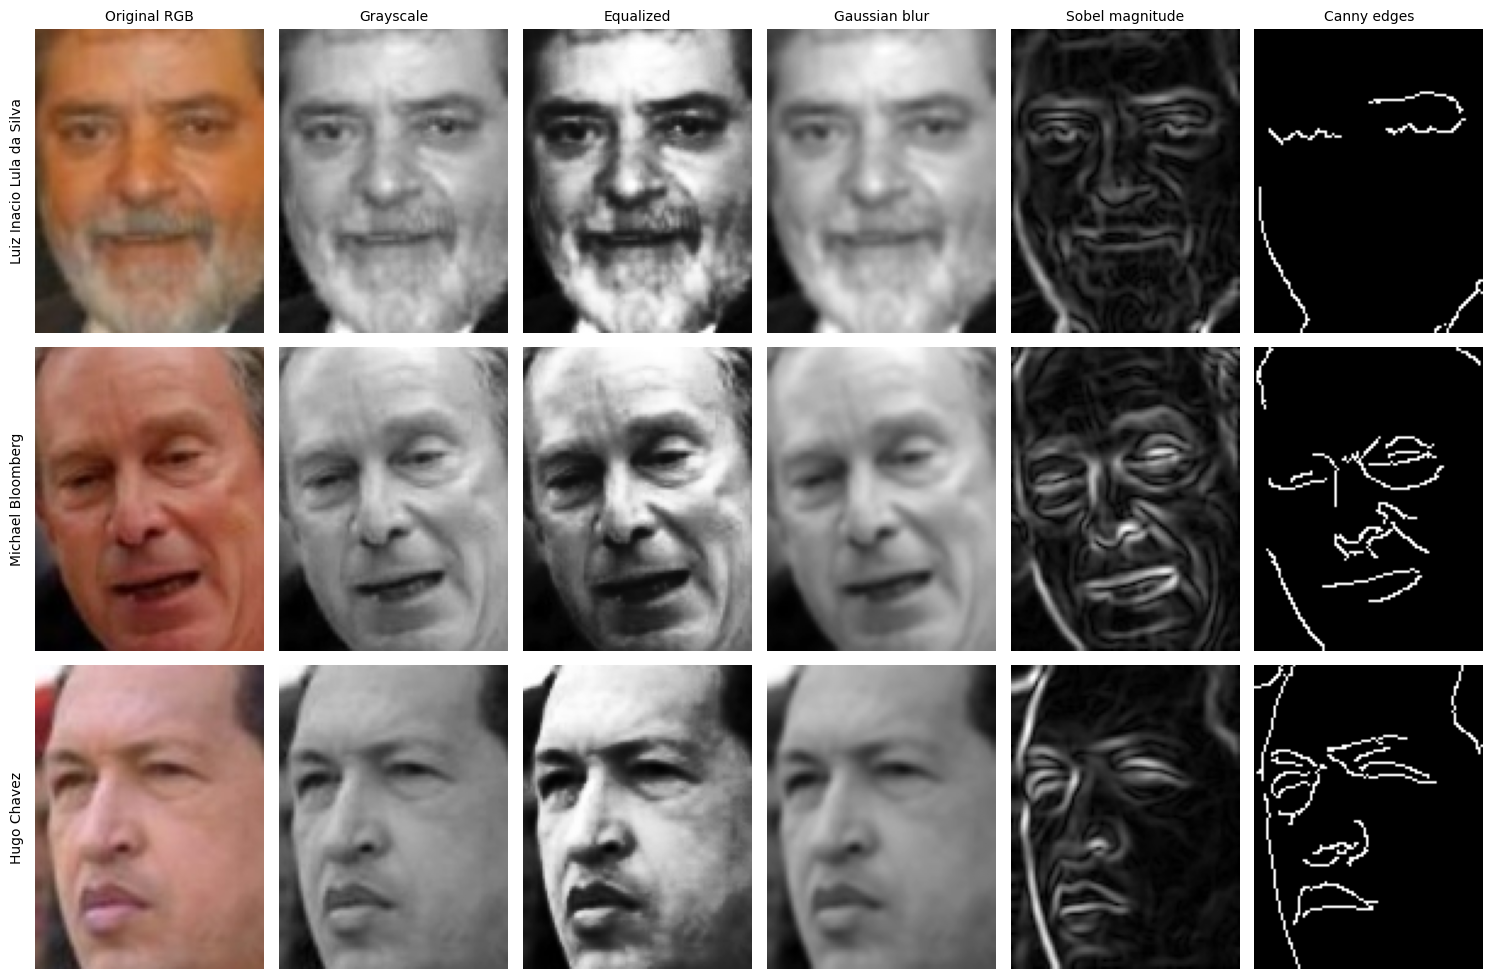

In [29]:
def to_uint8(img):
    return (np.clip(img, 0.0, 1.0) * 255).astype(np.uint8)

def classical_views(img):
    rgb = to_uint8(img)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    equalized = cv2.equalizeHist(gray)
    blurred = cv2.GaussianBlur(gray, (5, 5), 1.0)
    gx = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)
    sobel = cv2.magnitude(gx, gy)
    canny = cv2.Canny(blurred, 50, 150)
    return [("Original RGB", rgb), ("Grayscale", gray), ("Equalized", equalized),
            ("Gaussian blur", blurred), ("Sobel magnitude", sobel), ("Canny edges", canny)]

rng = np.random.default_rng(SEED)
picks = rng.choice(len(X_train), 3, replace=False)

fig, axes = plt.subplots(len(picks), 6, figsize=(15, 3.3 * len(picks)))
for r, idx in enumerate(picks):
    for ax, (title, view) in zip(axes[r], classical_views(X_train[idx])):
        ax.imshow(view, cmap=None if view.ndim == 3 else "gray")
        ax.set_title(title if r == 0 else "", fontsize=10)
        ax.axis("off")
    axes[r][0].text(-0.05, 0.5, class_names[y_train[idx]], transform=axes[r][0].transAxes,
                    rotation=90, va="center", ha="right", fontsize=10)
plt.tight_layout()
plt.show()

### How far do handcrafted features get us?

To make the comparison concrete, we build a complete **classical pipeline** and score it on the validation set:

1. Convert each face to grayscale.
2. Extract **HOG (Histogram of Oriented Gradients)** features. HOG divides the image into small cells and records the distribution of edge directions in each, so it is a compact, hand-designed descriptor of facial structure.
3. Train a **linear SVM** on those features. We use `class_weight="balanced"` so the large classes don't dominate.

This gives us a real accuracy number for the "before deep learning" approach, so the CNN and transfer-learning results have something honest to be compared against, alongside the majority-class baseline.

In [30]:
import time
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

def hog_features(images):
    feats = []
    for img in images:
        gray = cv2.cvtColor(to_uint8(img), cv2.COLOR_RGB2GRAY)
        feats.append(hog(gray, orientations=9, pixels_per_cell=(8, 8),
                         cells_per_block=(2, 2), block_norm="L2-Hys"))
    return np.array(feats, dtype=np.float32)

t0 = time.time()
H_train, H_val = hog_features(X_train), hog_features(X_val)
print(f"HOG feature vector length: {H_train.shape[1]}  (raw image has {h * w * c} values)")

svm = LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=SEED)
svm.fit(H_train, y_train)
elapsed = time.time() - t0

val_pred = svm.predict(H_val)
hog_val_acc = accuracy_score(y_val, val_pred)
hog_val_f1 = f1_score(y_val, val_pred, average="macro")
print(f"\nHOG + LinearSVC  ->  val accuracy: {hog_val_acc:.1%} | val macro-F1: {hog_val_f1:.3f}"
      f" | time: {elapsed:.0f}s")
print(f"Majority baseline ->  val accuracy: {BASELINE_VAL:.1%}")

HOG feature vector length: 5040  (raw image has 35250 values)

HOG + LinearSVC  ->  val accuracy: 75.3% | val macro-F1: 0.685 | time: 36s
Majority baseline ->  val accuracy: 17.4%


### Interpretation: split, classical filters and the HOG baseline

**The split**
- The 3,023 images became **2,116 train / 453 validation / 454 test**, and all 62 identities appear in every split. The majority-class share is 17.5%, 17.4% and 17.6% respectively, so the stratification did what it should: each split is a faithful miniature of the whole dataset, and the baseline to beat is about **17.4% on validation** and **17.6% on test**.
- Training has only about 34 images per identity on average (2,116 / 62), and the smallest identity has just **14**. That is very little data per class, which is a warning for the CNN later. It will likely need data augmentation and pretrained features to work well.
- The smallest identities have only **3 images** in validation and in test. One misclassified face moves that class's recall by 33 percentage points, so per-class scores for rare identities will be noisy. We should read them as rough signals and rely on aggregate numbers, and we should not over-tune on them.

**What the classical filters show**
- **Grayscale** discards colour. The orange, red and pink skin tones in the three faces vanish, but the structure that identifies the person (eyes, nose, mouth, jaw) is fully preserved. This suggests colour is largely a nuisance variable (lighting, white balance, film) and not an identity cue.
- **Histogram equalization** stretches contrast dramatically, and it makes the beard texture and the eye sockets much more visible. But it is a global operation, so it also exaggerates harsh shadows (compare the deep shadows on the third face). It helps some images and can hurt others.
- **Gaussian blur** softens noise and fine texture, which is why it is applied before edge detection and not as a goal in itself.
- **Sobel** lights up the eyebrows, eyelids, nostrils, mouth and face outline. That confirms identity information lives in local intensity changes around facial landmarks. However, it also responds to shadows, the hairline and the collar, which say nothing about identity, and it stays weak on low-contrast regions of the first face.
- **Canny** shows the main weakness of handcrafted pipelines. With the *same* fixed thresholds (50 / 150), it produces a rich sketch of the second and third faces but only a few fragments for the first face, where the eyes and nose are almost missing. The parameters were chosen by a human and do not adapt to each image's contrast and lighting, so they don't generalize. A CNN avoids this by **learning** its filters from data, and those filters adapt to what the task needs.

**The HOG + linear SVM baseline**
- HOG compresses each image from **35,250 raw values to 5,040 features** (about 7x smaller) by summarising edge directions in small cells. With a plain linear classifier on top, this reaches **75.3% validation accuracy and 0.685 macro-F1**, which is about **4.3x the 17.4% majority baseline**. So hand-designed gradient features already carry a lot of identity information.
- Macro-F1 (0.685) sits about 7 points below accuracy (75.3%). Accuracy is dominated by the large identities, while macro-F1 weights all 62 identities equally, so the gap tells us the classifier does noticeably worse on rare identities, even with `class_weight="balanced"`. This is why macro-F1 will be our main comparison metric.
- Cost was low: about **40 seconds on CPU**, with no GPU and no deep learning involved. Any deep model has to justify its extra compute against this.
- **Caution on the 75.3%:** LFW is built from news photographs, so the same person often appears in several near-identical shots from one event. A validation image may therefore have a near-duplicate in the training set, which would flatter *any* model, including this one. We can't confirm that from the current output, so we treat 75.3% as an optimistic yardstick for these particular splits and not as a guarantee of how the system would do on genuinely new photos.

**Decisions carried forward**
1. Reuse these exact splits (`X_train / X_val / X_test`) for every model, so the comparison is fair. The test set stays untouched until the final evaluation.
2. Record the classical row for the final comparison table: HOG + LinearSVC, 5,040 features, **val accuracy 75.3%, macro-F1 0.685, 36 s on CPU**.
3. The CNN has to beat both the 17.4% majority baseline and this 75.3% to justify its cost. We will judge on macro-F1 as well as accuracy.
4. With about 34 images per identity, plan for **data augmentation** (flips, small shifts, brightness changes) when we train the CNN.


## 4. Baseline CNN

HOG used features a human designed. A **Convolutional Neural Network** learns its own filters directly from the pixels, so the "Canny problem" from the previous section (fixed parameters that don't adapt) goes away.

**Design choices, and why**

| Choice | Reason |
|---|---|
| 4 blocks of Conv → BatchNorm → ReLU → MaxPool, with 32/64/128/256 filters | Early layers learn edges and textures, later layers combine them into parts of faces. Filter counts double as the spatial size halves. |
| Global average pooling instead of a big `Flatten → Dense` | Far fewer parameters, so less overfitting on ~34 images per identity |
| Dropout (0.4) before the classifier | Regularization |
| Data augmentation (flip, small rotation/shift, brightness/contrast) | Creates new plausible views of each face, which matters with so little data. It is only active during training. |
| Softened class weights | Rare identities count more in the loss. Fully "balanced" weights would span a 26x range, which can destabilize training, so we use their square root. |
| Early stopping on validation loss + learning-rate reduction | Stops when the model starts memorising the training set and keeps the best weights |

We also start a **results table** so every model, classical or deep, is recorded in one place for the final comparison.

In [31]:
from tensorflow.keras import layers
from sklearn.metrics import f1_score, precision_recall_fscore_support, confusion_matrix

results = {}

def record(name, val_acc, val_f1, params, train_seconds):
    results[name] = dict(val_acc=val_acc, val_macro_f1=val_f1, params=params, train_seconds=train_seconds)

# Row 1: predicting the most common identity for everyone
maj_pred = np.full_like(y_val, majority_class)
record("Majority class", BASELINE_VAL, f1_score(y_val, maj_pred, average="macro", zero_division=0), 0, 0)

# Row 2: HOG + LinearSVC from the previous section
record("HOG + LinearSVC", hog_val_acc, hog_val_f1, svm.coef_.size + svm.intercept_.size, elapsed)

for name, r in results.items():
    print(f"{name:16s} val acc {r['val_acc']:.1%} | macro-F1 {r['val_macro_f1']:.3f} | params {r['params']:,}")

Majority class   val acc 17.4% | macro-F1 0.005 | params 0
HOG + LinearSVC  val acc 75.3% | macro-F1 0.685 | params 312,542


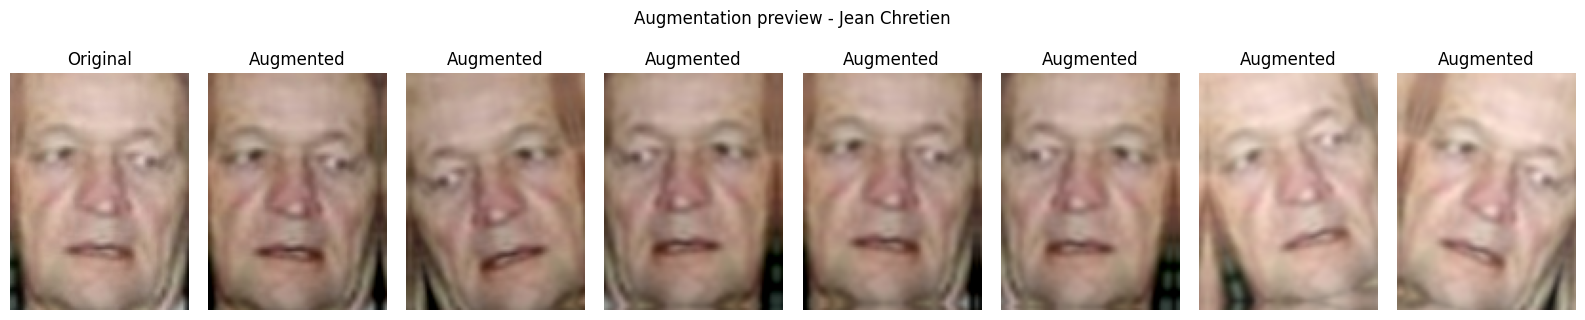

In [32]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomBrightness(0.1, value_range=(0.0, 1.0)),
    layers.RandomContrast(0.1),
], name="augmentation")

# What does augmentation actually produce? One training face, 7 random variants.
sample = X_train[:1]
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
axes[0].imshow(sample[0]); axes[0].set_title("Original")
for ax in axes[1:]:
    aug = data_augmentation(sample, training=True)[0].numpy()
    ax.imshow(np.clip(aug, 0, 1)); ax.set_title("Augmented")
for ax in axes: ax.axis("off")
plt.suptitle(f"Augmentation preview - {class_names[y_train[0]]}", y=1.05)
plt.tight_layout()
plt.show()

In [33]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def build_cnn():
    inputs = keras.Input(shape=(h, w, c))
    x = data_augmentation(inputs)          # only active while training
    for filters in (32, 64, 128, 256):
        x = conv_block(x, filters)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn")

keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
cnn.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 125, 94, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 125, 94, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 125, 94, 32)    │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 125, 94, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 125, 94, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 62, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 62, 47, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 62, 47, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 62, 47, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 31, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 31, 23, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 31, 23, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 31, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 15, 11, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 15, 11, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 15, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 62)             │        15,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 405,790 (1.55 MB)

 Trainable params: 404,830 (1.54 MB)

 Non-trainable params: 960 (3.75 KB)

In [34]:
from sklearn.utils.class_weight import compute_class_weight

balanced = compute_class_weight("balanced", classes=np.arange(n_classes), y=y_train)
class_weight = {i: float(wt) ** 0.5 for i, wt in enumerate(balanced)}   # softened
print(f"Fully balanced weights range {balanced.min():.2f} - {balanced.max():.2f} "
      f"({balanced.max() / balanced.min():.0f}x); softened range "
      f"{min(class_weight.values()):.2f} - {max(class_weight.values()):.2f} "
      f"({max(class_weight.values()) / min(class_weight.values()):.0f}x)")

EPOCHS = 150
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
]

t0 = time.time()
history = cnn.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=EPOCHS, batch_size=32,
                  class_weight=class_weight,
                  callbacks=callbacks, verbose=2)
cnn_seconds = time.time() - t0
print(f"\nTrained for {len(history.history['loss'])} epochs in {cnn_seconds:.0f}s")

Fully balanced weights range 0.09 - 2.44 (26x); softened range 0.30 - 1.56 (5x)
Epoch 1/150
67/67 - 10s - 146ms/step - accuracy: 0.0846 - loss: 3.9280 - val_accuracy: 0.0199 - val_loss: 4.0336 - learning_rate: 0.0010
Epoch 2/150
67/67 - 3s - 39ms/step - accuracy: 0.1139 - loss: 3.6554 - val_accuracy: 0.0199 - val_loss: 4.0208 - learning_rate: 0.0010
Epoch 3/150
67/67 - 3s - 39ms/step - accuracy: 0.1196 - loss: 3.5855 - val_accuracy: 0.0199 - val_loss: 4.1209 - learning_rate: 0.0010
Epoch 4/150
67/67 - 3s - 41ms/step - accuracy: 0.1248 - loss: 3.5348 - val_accuracy: 0.0221 - val_loss: 4.0569 - learning_rate: 0.0010
Epoch 5/150
67/67 - 3s - 41ms/step - accuracy: 0.1257 - loss: 3.4734 - val_accuracy: 0.0375 - val_loss: 3.9043 - learning_rate: 0.0010
Epoch 6/150
67/67 - 3s - 41ms/step - accuracy: 0.1531 - loss: 3.3865 - val_accuracy: 0.0132 - val_loss: 4.0534 - learning_rate: 0.0010
Epoch 7/150
67/67 - 3s - 41ms/step - accuracy: 0.1578 - loss: 3.3197 - val_accuracy: 0.0530 - val_loss: 3.91

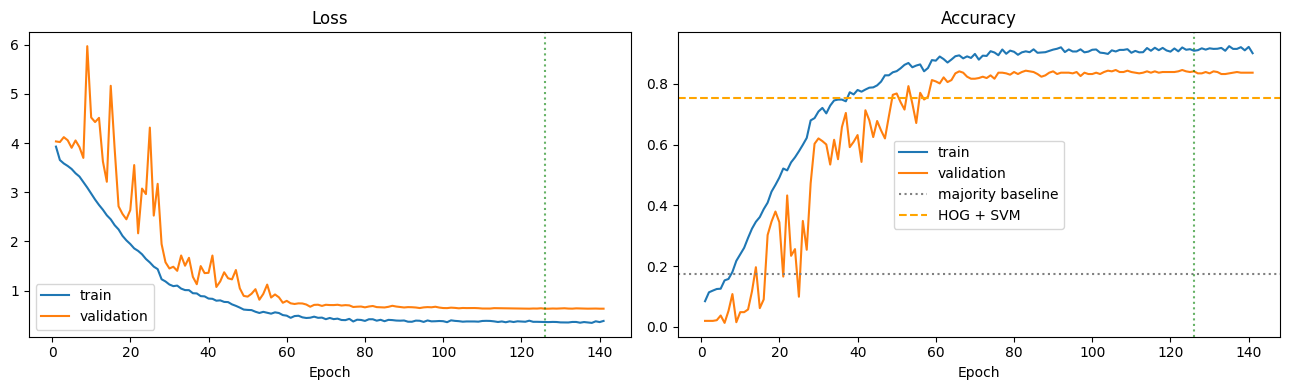

Best epoch (lowest val loss): 126


In [35]:
hist = history.history
best_epoch = int(np.argmin(hist["val_loss"]))
epochs_ran = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_ran, hist["loss"], label="train")
axes[0].plot(epochs_ran, hist["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch")
axes[1].plot(epochs_ran, hist["accuracy"], label="train")
axes[1].plot(epochs_ran, hist["val_accuracy"], label="validation")
axes[1].axhline(BASELINE_VAL, color="gray", ls=":", label="majority baseline")
axes[1].axhline(hog_val_acc, color="orange", ls="--", label="HOG + SVM")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch")
for ax in axes:
    ax.axvline(best_epoch + 1, color="green", ls=":", alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.show()
print(f"Best epoch (lowest val loss): {best_epoch + 1}")

In [36]:
val_prob = cnn.predict(X_val, batch_size=64, verbose=0)
val_pred = val_prob.argmax(axis=1)

cnn_val_acc = (val_pred == y_val).mean()
cnn_val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
top5_acc = np.mean([yt in row for yt, row in zip(y_val, np.argsort(val_prob, axis=1)[:, -5:])])
record("Baseline CNN", cnn_val_acc, cnn_val_f1, cnn.count_params(), cnn_seconds)

print(f"Baseline CNN  ->  val accuracy: {cnn_val_acc:.1%} | top-5 accuracy: {top5_acc:.1%} | macro-F1: {cnn_val_f1:.3f}\n")
print(f"{'Model':16s} {'val acc':>8s} {'macro-F1':>9s} {'params':>10s} {'train time':>11s}")
for name, r in results.items():
    print(f"{name:16s} {r['val_acc']:8.1%} {r['val_macro_f1']:9.3f} {r['params']:10,d} {r['train_seconds']:9.0f} s")

# Where does it fail? Per-identity recall on validation
_, recall, _, support = precision_recall_fscore_support(
    y_val, val_pred, labels=np.arange(n_classes), zero_division=0)
print(f"\nIdentities never recognised (recall = 0): {(recall == 0).sum()} of {n_classes}")
print("Weakest identities:")
for i in np.argsort(recall)[:8]:
    print(f"  {class_names[i]:25s} recall {recall[i]:.0%}  ({support[i]} val images)")

# Most common mistakes
cm = confusion_matrix(y_val, val_pred, labels=np.arange(n_classes))
np.fill_diagonal(cm, 0)
print("\nMost frequent confusions (true -> predicted):")
for flat in np.argsort(cm, axis=None)[::-1][:6]:
    t, p = divmod(flat, n_classes)
    print(f"  {class_names[t]:22s} -> {class_names[p]:22s} x{cm[t, p]}")

Baseline CNN  ->  val accuracy: 84.1% | top-5 accuracy: 95.6% | macro-F1: 0.786

Model             val acc  macro-F1     params  train time
Majority class      17.4%     0.005          0         0 s
HOG + LinearSVC     75.3%     0.685    312,542        36 s
Baseline CNN        84.1%     0.786    405,790       385 s

Identities never recognised (recall = 0): 1 of 62
Weakest identities:
  Jennifer Lopez            recall 0%  (3 val images)
  Jeremy Greenstock         recall 25%  (4 val images)
  Rudolph Giuliani          recall 25%  (4 val images)
  Alejandro Toledo          recall 33%  (6 val images)
  Igor Ivanov               recall 33%  (3 val images)
  Angelina Jolie            recall 33%  (3 val images)
  Michael Bloomberg         recall 33%  (3 val images)
  Hamid Karzai              recall 50%  (4 val images)

Most frequent confusions (true -> predicted):
  Vladimir Putin         -> Jacques Chirac         x2
  Tony Blair             -> Gerhard Schroeder      x2
  Michael Bloomber

### Interpretation: baseline CNN

**Headline result**
- The CNN reaches **84.1% validation accuracy, 95.6% top-5 accuracy and 0.786 macro-F1**, against 75.3% / 0.685 for HOG + SVM and 17.4% for the majority baseline. That is about **9 points of accuracy (roughly 40 more of the 453 validation faces) and 0.10 of macro-F1** over the classical pipeline.
- That gain is larger than the sampling noise on a validation set this small (about ±1.7 points for 453 images), so it is probably real.
- Two runs of this same code can differ, because GPU training is not exactly repeatable. So **differences of a point or two between models should not be over-interpreted**, and every number here comes from a single run.
- Top-5 accuracy of 95.6% says the right identity is almost always among the model's few best guesses, so its mistakes are mostly near-misses.

**How training went**
- **Slow, erratic start.** For roughly the first 35 epochs, training loss falls smoothly but validation is unstable: validation accuracy sits near 2% for the first ~8 epochs and validation loss spikes to almost 6 around epoch 9. A likely cause is BatchNorm: while the weights change quickly at the initial learning rate, its running statistics lag behind, so evaluation-mode predictions are unreliable. The learning rate was cut seven times (six halvings from 1e-3, then a final cut to the 1e-5 floor at epoch 110), and the curves settled once it had dropped, by about epoch 60.
- **Early stopping worked this time.** The best validation loss (0.632) came at epoch 126, and training stopped at epoch 141 after 15 epochs without improvement, restoring the best weights. Validation loss was already nearly flat (0.63 to 0.71) from around epoch 70, so much of the later training added very little. A small `min_delta` on the callback would have stopped sooner, and we use one in the next model.
- **Moderate overfitting.** At the best epoch, training accuracy is about 91% against 84% on validation, and the loss is 0.36 against 0.63. The training figures are measured with augmentation and dropout switched on, so they understate the model's true training accuracy. Augmentation, dropout and global average pooling kept the gap to a few points on only ~34 images per identity.

**Where it fails**
- Only **one identity is never recognised**: Jennifer Lopez (3 validation images). The other weakest identities (Jeremy Greenstock, Rudolph Giuliani, Alejandro Toledo, Igor Ivanov, Angelina Jolie, Michael Bloomberg) score 25% to 33% recall, but each has only 3 to 6 validation images, so a single mistake moves their recall by 17 to 33 points. These per-identity numbers are noisy and shouldn't be over-interpreted.
- Macro-F1 (0.786) still sits about 5.5 points below accuracy (84.1%), a slightly smaller gap than HOG's 6.8 points. Rare identities are still recognised worse than common ones.
- The most frequent confusions occur at most 2 times each, so there is **no strong systematic pattern**. The one weak signal is that Gerhard Schroeder is involved in three of the six most common confusions.

**Cost versus benefit**
- The CNN has 405,790 parameters, similar to the ~312,500 weights of the linear SVM, but it took **385 s on a T4 GPU against 36 s on CPU for HOG + SVM**, roughly 10x longer. The hardware differs, so this is a rough comparison and not a benchmark.
- For that extra cost we gain about 9 points of accuracy and 0.10 macro-F1, and we no longer hand-design the features.

**Caveats**
- The validation set was used for early stopping, the learning-rate schedule and picking the final weights, so these validation scores are slightly optimistic. The **test set is still untouched** and will give the honest estimate at the end.
- The near-duplicate-photo concern from the HOG section still applies: some validation faces may have near-twins in the training set, which flatters every model.

**Decisions carried forward**
1. Record the row: **Baseline CNN, 405,790 parameters, val accuracy 84.1%, macro-F1 0.786, 385 s (T4 GPU)**.
2. Add `min_delta` to early stopping so it ends training when improvement becomes negligible.
3. Next: **transfer learning**. A network pretrained on millions of images already knows edges, textures and shapes. With only ~34 images per identity, reusing those features should help most on the rare identities where this model is weakest.


## 5. Transfer learning with a pretrained CNN

Our baseline CNN had to learn *everything* (edges, textures, shapes, then faces) from only ~2,100 images. **Transfer learning** starts from a network that has already learned general visual features from over a million ImageNet photos and adapts it to our task. This should help most where our data is thinnest: the rare identities.

**Backbone: MobileNetV2** (about 2.3M parameters). It is small and fast, which matters when compute and memory are limited.

**Two-phase training**

| Phase | What is trainable | Learning rate | Purpose |
|---|---|---|---|
| 1. Feature extraction | Only the new classification head | 1e-3 | Teach the head to read the pretrained features without disturbing them |
| 2. Fine-tuning | Head + the top 40 layers of the backbone | 1e-4 | Nudge the high-level features toward faces |

**Input handling**
- Images are resized to 160x120 (same 4:3 shape as our 125x94 faces, so nothing is stretched) and rescaled from `[0, 1]` to `[-1, 1]`, which is what MobileNetV2 was trained on.
- The backbone's BatchNorm layers stay in inference mode throughout, so its learned statistics aren't corrupted by our small batches.
- You will see a Keras warning about the input shape. It is harmless: the network is fully convolutional, so the standard ImageNet weights work at other sizes.

We reuse the same splits, augmentation and softened class weights as the baseline CNN, and add `min_delta` to early stopping so training ends when improvement becomes negligible.

In [37]:
from tensorflow.keras.applications import MobileNetV2

# Keep the baseline CNN's predictions so the two models can be compared identity by identity
cnn_val_pred = cnn.predict(X_val, batch_size=64, verbose=0).argmax(axis=1)
_, cnn_recall, _, val_support = precision_recall_fscore_support(
    y_val, cnn_val_pred, labels=np.arange(n_classes), zero_division=0)

def ms_per_image(model, X_eval):
    model.predict(X_eval[:64], verbose=0)                       # warm-up
    start = time.time()
    model.predict(X_eval, batch_size=64, verbose=0)
    return (time.time() - start) / len(X_eval) * 1000

def report(name, model, train_seconds):
    prob = model.predict(X_val, batch_size=64, verbose=0)
    pred = prob.argmax(axis=1)
    acc = (pred == y_val).mean()
    f1 = f1_score(y_val, pred, average="macro", zero_division=0)
    top5 = np.mean([yt in row for yt, row in zip(y_val, np.argsort(prob, axis=1)[:, -5:])])
    record(name, acc, f1, model.count_params(), train_seconds)
    print(f"{name}  ->  val accuracy: {acc:.1%} | top-5: {top5:.1%} | macro-F1: {f1:.3f} | "
          f"{ms_per_image(model, X_val):.2f} ms/image")
    return pred

latency = {"Baseline CNN": ms_per_image(cnn, X_val)}
print(f"Baseline CNN inference: {latency['Baseline CNN']:.2f} ms/image")

Baseline CNN inference: 1.34 ms/image


In [38]:
IMG_H, IMG_W = 160, 120

def build_transfer():
    base = MobileNetV2(input_shape=(IMG_H, IMG_W, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = keras.Input(shape=(h, w, c))
    x = data_augmentation(inputs)                    # same augmentation as the baseline CNN
    x = layers.Resizing(IMG_H, IMG_W)(x)
    x = layers.Rescaling(2.0, offset=-1.0)(x)        # [0, 1] -> [-1, 1]
    x = base(x, training=False)                      # BatchNorm stays in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_transfer"), base

keras.utils.set_random_seed(SEED)
tl_model, base = build_transfer()
tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

trainable = sum(int(np.prod(v.shape)) for v in tl_model.trainable_weights)
print(f"Backbone layers: {len(base.layers)}")
print(f"Total parameters    : {tl_model.count_params():,}")
print(f"Trainable (phase 1) : {trainable:,}  <- only the new head")

/tmp/ipykernel_4206/3259721878.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNetV2(input_shape=(IMG_H, IMG_W, 3), include_top=False, weights="imagenet")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Backbone layers: 154
Total parameters    : 2,337,406
Trainable (phase 1) : 79,422  <- only the new head


In [39]:
def make_callbacks(patience):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, min_delta=0.005,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ]

PHASE1_EPOCHS = 40
t0 = time.time()
history1 = tl_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=PHASE1_EPOCHS, batch_size=32,
                        class_weight=class_weight, callbacks=make_callbacks(8), verbose=2)
phase1_seconds = time.time() - t0
print(f"\nPhase 1: {len(history1.history['loss'])} epochs in {phase1_seconds:.0f}s")

phase1_pred = report("MobileNetV2 (head only)", tl_model, phase1_seconds)

Epoch 1/40
67/67 - 12s - 177ms/step - accuracy: 0.1120 - loss: 4.0603 - val_accuracy: 0.2539 - val_loss: 3.0108 - learning_rate: 0.0010
Epoch 2/40
67/67 - 2s - 33ms/step - accuracy: 0.2680 - loss: 2.8470 - val_accuracy: 0.3885 - val_loss: 2.5248 - learning_rate: 0.0010
Epoch 3/40
67/67 - 2s - 33ms/step - accuracy: 0.3790 - loss: 2.3448 - val_accuracy: 0.4570 - val_loss: 2.2316 - learning_rate: 0.0010
Epoch 4/40
67/67 - 2s - 33ms/step - accuracy: 0.4631 - loss: 2.0473 - val_accuracy: 0.5011 - val_loss: 2.0487 - learning_rate: 0.0010
Epoch 5/40
67/67 - 3s - 39ms/step - accuracy: 0.5165 - loss: 1.7761 - val_accuracy: 0.5430 - val_loss: 1.8923 - learning_rate: 0.0010
Epoch 6/40
67/67 - 2s - 34ms/step - accuracy: 0.5430 - loss: 1.6524 - val_accuracy: 0.5232 - val_loss: 1.8228 - learning_rate: 0.0010
Epoch 7/40
67/67 - 2s - 33ms/step - accuracy: 0.5671 - loss: 1.5121 - val_accuracy: 0.5607 - val_loss: 1.7441 - learning_rate: 0.0010
Epoch 8/40
67/67 - 2s - 33ms/step - accuracy: 0.5931 - loss:

In [40]:
FINE_TUNE_LAYERS = 40
PHASE2_EPOCHS = 40

base.trainable = True
for layer in base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False                          # keep the early, generic layers frozen
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False                      # keep BatchNorm statistics fixed

tl_model.compile(optimizer=keras.optimizers.Adam(1e-4),   # recompile after changing trainable flags
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

trainable = sum(int(np.prod(v.shape)) for v in tl_model.trainable_weights)
print(f"Trainable parameters (phase 2): {trainable:,} of {tl_model.count_params():,}")

t0 = time.time()
history2 = tl_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=PHASE2_EPOCHS, batch_size=32,
                        class_weight=class_weight, callbacks=make_callbacks(8), verbose=2)
phase2_seconds = time.time() - t0
print(f"\nPhase 2: {len(history2.history['loss'])} epochs in {phase2_seconds:.0f}s")

Trainable parameters (phase 2): 1,742,782 of 2,337,406
Epoch 1/40
67/67 - 18s - 263ms/step - accuracy: 0.6725 - loss: 1.0841 - val_accuracy: 0.6843 - val_loss: 1.2060 - learning_rate: 1.0000e-04
Epoch 2/40
67/67 - 3s - 47ms/step - accuracy: 0.7306 - loss: 0.8229 - val_accuracy: 0.7152 - val_loss: 1.0738 - learning_rate: 1.0000e-04
Epoch 3/40
67/67 - 3s - 39ms/step - accuracy: 0.8091 - loss: 0.5992 - val_accuracy: 0.7417 - val_loss: 0.9303 - learning_rate: 1.0000e-04
Epoch 4/40
67/67 - 3s - 38ms/step - accuracy: 0.8209 - loss: 0.5300 - val_accuracy: 0.7042 - val_loss: 1.1277 - learning_rate: 1.0000e-04
Epoch 5/40
67/67 - 3s - 38ms/step - accuracy: 0.8332 - loss: 0.4784 - val_accuracy: 0.7351 - val_loss: 1.1349 - learning_rate: 1.0000e-04
Epoch 6/40
67/67 - 3s - 39ms/step - accuracy: 0.8521 - loss: 0.4437 - val_accuracy: 0.7196 - val_loss: 1.1026 - learning_rate: 1.0000e-04
Epoch 7/40
67/67 - 3s - 44ms/step - accuracy: 0.9159 - loss: 0.2523 - val_accuracy: 0.8102 - val_loss: 0.7775 - lea

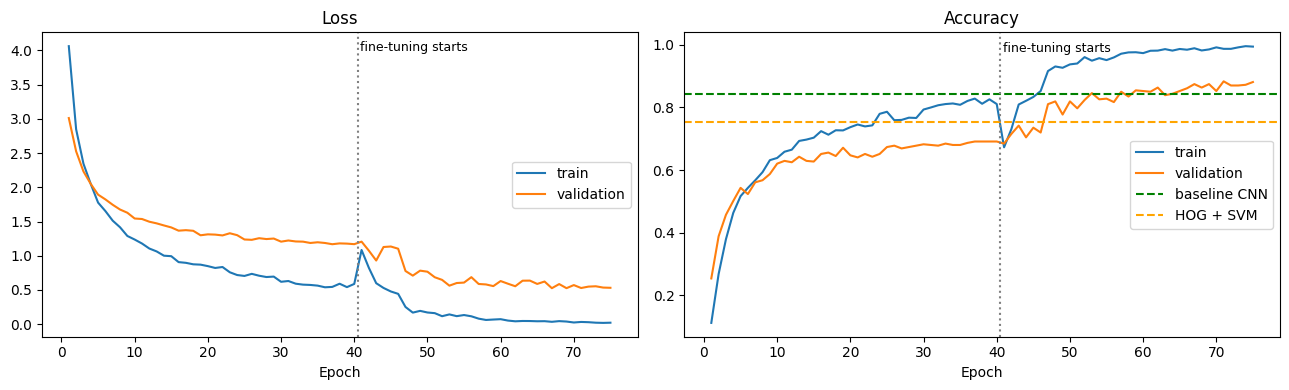

In [41]:
h1, h2 = history1.history, history2.history
loss = h1["loss"] + h2["loss"];            val_loss = h1["val_loss"] + h2["val_loss"]
acc = h1["accuracy"] + h2["accuracy"];     val_acc = h1["val_accuracy"] + h2["val_accuracy"]
boundary = len(h1["loss"]) + 0.5
epochs_all = range(1, len(loss) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_all, loss, label="train")
axes[0].plot(epochs_all, val_loss, label="validation")
axes[0].set_title("Loss")
axes[1].plot(epochs_all, acc, label="train")
axes[1].plot(epochs_all, val_acc, label="validation")
axes[1].axhline(cnn_val_acc, color="green", ls="--", label="baseline CNN")
axes[1].axhline(hog_val_acc, color="orange", ls="--", label="HOG + SVM")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.axvline(boundary, color="gray", ls=":")
    ax.text(boundary + 0.3, ax.get_ylim()[1] * 0.97, "fine-tuning starts", va="top", fontsize=9)
    ax.set_xlabel("Epoch"); ax.legend(loc="center right")
plt.tight_layout()
plt.show()

In [42]:
tl_seconds = phase1_seconds + phase2_seconds
tl_pred = report("MobileNetV2 (fine-tuned)", tl_model, tl_seconds)
latency["MobileNetV2 (fine-tuned)"] = ms_per_image(tl_model, X_val)

print(f"\n{'Model':26s} {'val acc':>8s} {'macro-F1':>9s} {'params':>10s} {'train time':>11s}")
for name, r in results.items():
    print(f"{name:26s} {r['val_acc']:8.1%} {r['val_macro_f1']:9.3f} {r['params']:10,d} {r['train_seconds']:9.0f} s")

# Identity-by-identity: did transfer learning help where the baseline CNN was weakest?
_, tl_recall, _, _ = precision_recall_fscore_support(
    y_val, tl_pred, labels=np.arange(n_classes), zero_division=0)
print(f"\nvs baseline CNN, per identity: better on {(tl_recall > cnn_recall).sum()}, "
      f"worse on {(tl_recall < cnn_recall).sum()}, unchanged on {(tl_recall == cnn_recall).sum()} of {n_classes}")
print(f"Identities never recognised: baseline CNN {(cnn_recall == 0).sum()} -> MobileNetV2 {(tl_recall == 0).sum()}")
print("\nBaseline CNN's 8 weakest identities:")
print(f"  {'identity':25s} {'baseline':>9s} {'MobileNetV2':>12s}  val images")
for i in np.argsort(cnn_recall)[:8]:
    print(f"  {class_names[i]:25s} {cnn_recall[i]:9.0%} {tl_recall[i]:12.0%}  {val_support[i]}")

MobileNetV2 (fine-tuned)  ->  val accuracy: 87.4% | top-5: 97.1% | macro-F1: 0.820 | 2.27 ms/image

Model                       val acc  macro-F1     params  train time
Majority class                17.4%     0.005          0         0 s
HOG + LinearSVC               75.3%     0.685    312,542        36 s
Baseline CNN                  84.1%     0.786    405,790       385 s
MobileNetV2 (head only)       69.1%     0.602  2,337,406       100 s
MobileNetV2 (fine-tuned)      87.4%     0.820  2,337,406       212 s

vs baseline CNN, per identity: better on 24, worse on 16, unchanged on 22 of 62
Identities never recognised: baseline CNN 1 -> MobileNetV2 1

Baseline CNN's 8 weakest identities:
  identity                   baseline  MobileNetV2  val images
  Jennifer Lopez                   0%          67%  3
  Jeremy Greenstock               25%         100%  4
  Rudolph Giuliani                25%          50%  4
  Alejandro Toledo                33%          50%  6
  Igor Ivanov              

### Interpretation: transfer learning with MobileNetV2

**Headline result**
- After fine-tuning, MobileNetV2 reaches **87.4% validation accuracy, 97.1% top-5 accuracy and 0.820 macro-F1**. That beats the baseline CNN (84.1% / 0.786) by about **3 points of accuracy (roughly 15 faces) and 0.034 macro-F1**, HOG + SVM (75.3% / 0.685) by about 12 points, and the majority baseline (17.4%) by a wide margin.
- Be careful with the CNN comparison. The gap is small, it comes from a single run, and GPU training isn't exactly repeatable, so a re-run could move either model by a point or two. The advantage over the baseline is **suggestive, not conclusive**. The test set will give a second, independent look, and repeating the runs with different seeds would tighten it further.

**What each phase contributed**
- **Head only (phase 1): 69.1% accuracy, 0.602 macro-F1.** With the backbone frozen, the model is *worse* than both the baseline CNN and HOG. Validation accuracy stalls around 68% to 69% from about epoch 25, while training accuracy keeps climbing to about 83%. Only the small head is learning, and generic ImageNet features (everyday objects, textures) are not enough on their own to tell individual faces apart.
- **Fine-tuning (phase 2): 87.4%, an 18-point jump.** Once the top 40 backbone layers could adapt, the network specialised its high-level features to faces. Training loss briefly jumps at the start of fine-tuning (the newly unfrozen layers are disturbed), then falls quickly. Validation accuracy passes the baseline CNN's level after roughly 15 epochs of fine-tuning. **Fine-tuning is where transfer learning earns its keep here; a frozen backbone is not enough.**

**Overfitting**
- Training accuracy reaches about 99% (with augmentation and dropout on) while validation stays near 88%, and the loss gap is 0.02 against 0.53. This is a **larger gap than the baseline CNN's**: 1.7M trainable parameters can memorise ~2,100 training images.
- Validation loss stopped improving at epoch 27 of phase 2, and early stopping (with `min_delta`) halted training at epoch 35 and restored the best weights. Later epochs kept improving training accuracy but not validation, which is what overfitting looks like.

**Did it help the rare identities?**
- Per identity, transfer learning is **better on 24, worse on 16 and unchanged on 22** of 62. So the average gain hides a lot of churn, and it is not an improvement everywhere.
- Of the baseline CNN's 8 weakest identities, MobileNetV2 improved **6** (Jennifer Lopez 0% to 67%, Jeremy Greenstock 25% to 100%, Rudolph Giuliani 25% to 50%, Alejandro Toledo 33% to 50%, Angelina Jolie 33% to 67%, Michael Bloomberg 33% to 67%), left one unchanged (Hamid Karzai, 50%) and made one worse (Igor Ivanov, 33% to 0%). Igor Ivanov is now the single identity that is never recognised, where the baseline missed Jennifer Lopez instead.
- This is consistent with the idea that pretrained features help when data is scarce, but with only 3 to 6 validation images per identity, each of these changes rests on one or two faces. We treat it as encouraging evidence and not as proof.

**Cost**

| | Baseline CNN | MobileNetV2 (fine-tuned) |
|---|---|---|
| Parameters | 405,790 | 2,337,406 (1.74M trained in phase 2) |
| Training time (T4) | 385 s (141 epochs) | 212 s (40 + 35 epochs) |
| Inference | 1.34 ms/image | 2.27 ms/image |

- MobileNetV2 has about **5.8x more parameters** and is about **1.7x slower at inference**. Yet it **trained faster overall**, because starting from pretrained weights it needs far fewer epochs (75 against 141) to converge. The trade is a bigger, slower model at prediction time for a cheaper training run and slightly better accuracy.

**Caveats**
- The validation set again guided early stopping, the learning-rate schedule and the choice of weights, so these validation scores are slightly optimistic. The **test set is still untouched**.
- The near-duplicate-photo concern applies to every model here, including this one.
- All models are single runs, so small differences between them are within run-to-run noise.

**Decisions carried forward**
1. Record the rows: **MobileNetV2 head only, 69.1% / 0.602; MobileNetV2 fine-tuned, 87.4% / 0.820, 2,337,406 parameters, 212 s, 2.27 ms/image**.
2. Take the fine-tuned MobileNetV2 as the best candidate on validation, but treat its lead over the baseline CNN as tentative.
3. Next: a conceptual introduction to **Vision Transformers** and self-attention, then a **final comparison of all models on the untouched test set**, covering accuracy, macro-F1, generalization and computational cost.


## 6. Vision Transformers: the idea, and a look at self-attention

**Where CNNs fall short.** A convolution only looks at a small neighbourhood, so relating distant parts of a face (say, the eyes and the jawline) requires stacking many layers. CNNs also bake in strong assumptions: nearby pixels matter most, and the same filter is useful everywhere. Those assumptions are why our CNN could learn from only ~2,100 images.

**The Vision Transformer (ViT) idea.** Treat an image like a sentence:
1. Cut the image into fixed-size **patches** (e.g. 16x16 pixels), so each patch is a "word".
2. Flatten each patch and linearly project it into a **token** vector. Add a **positional embedding** so the model knows where each patch came from, and prepend a special **[CLS]** token that will summarise the image.
3. Pass the tokens through Transformer blocks, whose core is **self-attention**:

   `Attention(Q, K, V) = softmax(Q Kᵀ / √d) V`

   Every token produces a query (Q), a key (K) and a value (V). A token compares its query against **every** other token's key, and the softmax turns those scores into weights that sum to 1. The output is a weighted mix of the values. So from the very first layer, each patch can draw information from *any* other patch.
4. Classify from the final [CLS] token.

**What that costs and buys**
- **Global context from layer 1**, which suits faces, where identity depends on the *relationships* between features.
- **Far less built-in bias**, so ViTs generally need much more training data than CNNs. They are usually pre-trained on millions of images. Research has also used ViT backbones for face recognition, trained on millions of faces.
- **Quadratic cost:** with N tokens, every attention head builds an N x N matrix. Halving the patch size gives 4x the tokens and roughly 16x the attention cost.

**Why we don't train one here.** With ~34 images per identity, a ViT trained from scratch would have almost nothing to learn from, and even a small pretrained one (ViT-Base has ~86M parameters) is far beyond a sensible fine-tuning budget on 2,100 images. So instead of training, this section makes the mechanism concrete:
1. Cut one of our faces into patches.
2. Compute self-attention by hand.
3. See what a **pretrained** ViT attends to on our faces.
4. Compare model sizes.

*The last two steps use `transformers` and PyTorch for inference only. Colab has both preinstalled. The rest of the project stays in TensorFlow/Keras.*

*A note on the attention maps: our crops are very tight, so we place each face on a neutral grey canvas before giving it to the pretrained ViT. Without that margin, ViTs tend to park much of their attention on the image corners and borders. We keep the demo honest by treating attention maps as an illustration and not as proof of what the model "understands".*

Face image      : (1, 128, 96, 3)   (1, H, W, C)
Patch grid      : 8 x 6 = 48 patches
Each patch      : 16 x 16 x 3 = 768 numbers
Token tensor    : (1, 48, 768)   (batch, number of tokens, values per token)


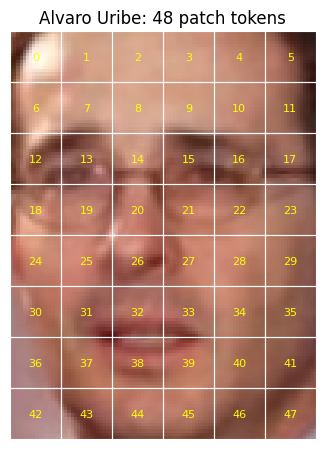

In [43]:
PATCH = 16
demo_idx = 0
face = X_val[demo_idx]                                        # (125, 94, 3)
face_resized = tf.image.resize(face[None], (128, 96)).numpy() # (1, 128, 96, 3) -> 8 x 6 patches of 16x16

patches = tf.image.extract_patches(face_resized,
                                   sizes=[1, PATCH, PATCH, 1], strides=[1, PATCH, PATCH, 1],
                                   rates=[1, 1, 1, 1], padding="VALID")
grid_h, grid_w = patches.shape[1], patches.shape[2]
tokens = tf.reshape(patches, (1, grid_h * grid_w, PATCH * PATCH * 3))

print(f"Face image      : {face_resized.shape}   (1, H, W, C)")
print(f"Patch grid      : {grid_h} x {grid_w} = {grid_h * grid_w} patches")
print(f"Each patch      : {PATCH} x {PATCH} x 3 = {PATCH * PATCH * 3} numbers")
print(f"Token tensor    : {tokens.shape}   (batch, number of tokens, values per token)")

fig, ax = plt.subplots(figsize=(3.6, 4.6))
ax.imshow(face_resized[0])
for r in range(grid_h):
    for cc in range(grid_w):
        ax.add_patch(plt.Rectangle((cc * PATCH - 0.5, r * PATCH - 0.5), PATCH, PATCH,
                                   fill=False, ec="white", lw=0.8))
        ax.text(cc * PATCH + PATCH / 2 - 0.5, r * PATCH + PATCH / 2 - 0.5, str(r * grid_w + cc),
                color="yellow", ha="center", va="center", fontsize=8)
ax.set_title(f"{class_names[y_val[demo_idx]]}: {grid_h * grid_w} patch tokens")
ax.axis("off")
plt.tight_layout()
plt.show()

Attention matrix : (1, 48, 48)  -> every one of the 48 tokens scores all 48
Row sums         : min 1.000, max 1.000  (softmax -> weights sum to 1)
Output tokens    : (1, 48, 768)  (same shape as the input tokens)


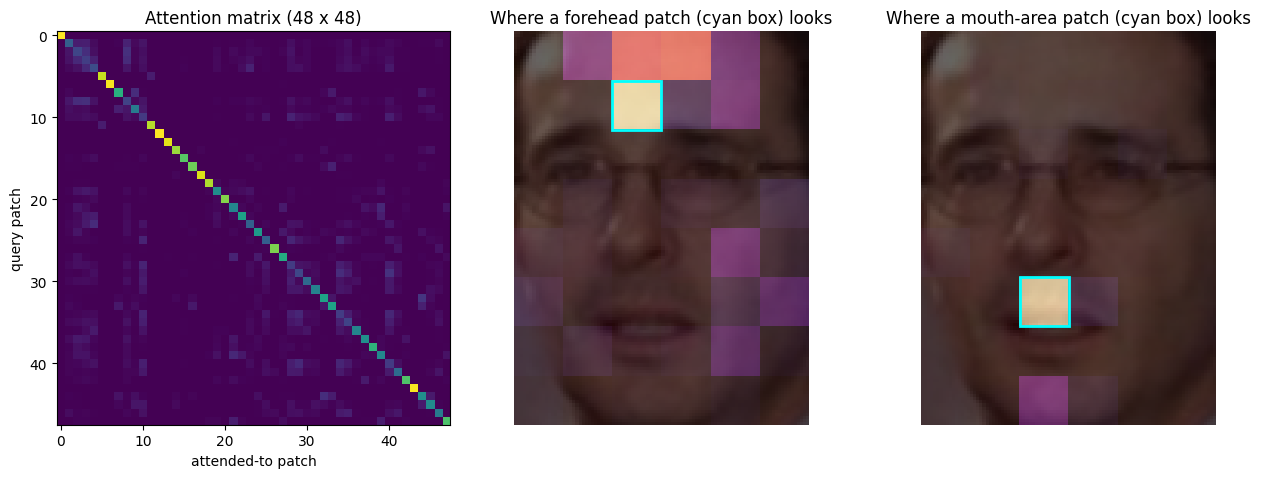

In [44]:
def self_attention(x, Wq, Wk, Wv):
    Q, K, V = x @ Wq, x @ Wk, x @ Wv
    scores = Q @ tf.transpose(K, [0, 2, 1]) / np.sqrt(K.shape[-1])   # (1, N, N)
    weights = tf.nn.softmax(scores, axis=-1)                          # each row sums to 1
    return weights @ V, weights

# Standardise each token (as a ViT's LayerNorm does) and use identity matrices for Wq, Wk, Wv.
# Nothing is learned here, so each patch simply attends to patches that look like itself.
# This shows the MECHANICS of attention, not what a trained model would do.
x = tf.constant((tokens - tf.reduce_mean(tokens, axis=-1, keepdims=True))
                / tf.math.reduce_std(tokens, axis=-1, keepdims=True))
I = tf.eye(x.shape[-1])
out, attn = self_attention(x, I, I, I)

print(f"Attention matrix : {attn.shape}  -> every one of the {attn.shape[1]} tokens scores all {attn.shape[2]}")
print(f"Row sums         : min {tf.reduce_min(tf.reduce_sum(attn, -1)).numpy():.3f}, "
      f"max {tf.reduce_max(tf.reduce_sum(attn, -1)).numpy():.3f}  (softmax -> weights sum to 1)")
print(f"Output tokens    : {out.shape}  (same shape as the input tokens)")

queries = {"a forehead patch": 1 * grid_w + 2, "a mouth-area patch": 5 * grid_w + 2}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
axes[0].imshow(attn[0].numpy(), cmap="viridis")
axes[0].set_title("Attention matrix (48 x 48)"); axes[0].set_xlabel("attended-to patch"); axes[0].set_ylabel("query patch")
for ax, (title, q) in zip(axes[1:], queries.items()):
    heat = tf.reshape(attn[0, q], (grid_h, grid_w)).numpy()
    ax.imshow(face_resized[0])
    ax.imshow(cv2.resize(heat, (face_resized.shape[2], face_resized.shape[1]), interpolation=cv2.INTER_NEAREST),
              cmap="magma", alpha=0.6)
    r, cc = divmod(q, grid_w)
    ax.add_patch(plt.Rectangle((cc * PATCH - 0.5, r * PATCH - 0.5), PATCH, PATCH, fill=False, ec="cyan", lw=2))
    ax.set_title(f"Where {title} (cyan box) looks"); ax.axis("off")
plt.tight_layout()
plt.show()

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

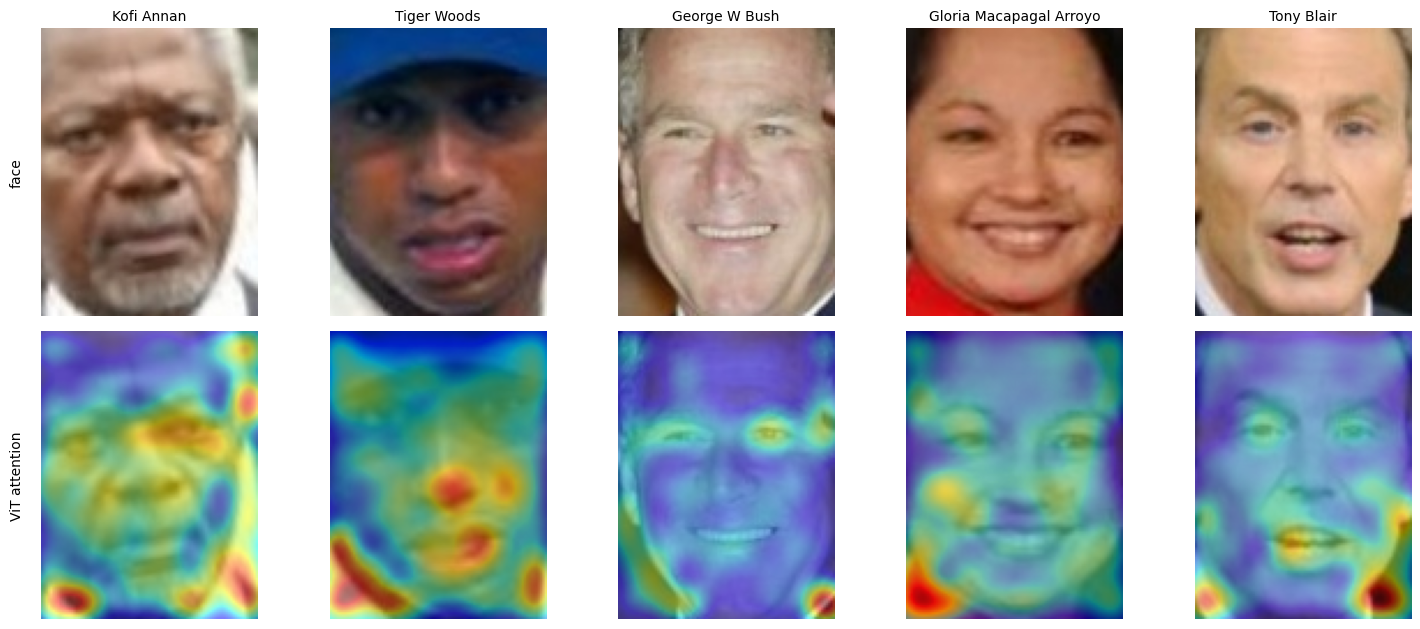

In [45]:
import torch
from transformers import ViTImageProcessor, ViTModel
from transformers import logging as hf_logging
hf_logging.set_verbosity_error()          # silences the harmless "unused classifier weights" notice

processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
vit = ViTModel.from_pretrained("google/vit-base-patch16-224", attn_implementation="eager",
                               add_pooling_layer=False).eval()

def attention_rollout(attentions):
    # Combine attention across all layers (Abnar & Zuidema, 2020): average the heads,
    # add the residual connection, re-normalise, then multiply layer by layer.
    n = attentions[0].shape[-1]
    rollout = torch.eye(n)
    for layer_attn in attentions:
        a = layer_attn[0].mean(dim=0) + torch.eye(n)
        a = a / a.sum(dim=-1, keepdim=True)
        rollout = a @ rollout
    return rollout[0, 1:]                 # [CLS] token's attention to the 196 image patches

FACE_H, FACE_W = 160, 120
TOP, LEFT = (224 - FACE_H) // 2, (224 - FACE_W) // 2

def on_canvas(img_float):
    # Our crops are very tight, with almost no background. A ViT pretrained on ImageNet expects objects
    # with surrounding context, so we place the face on a neutral grey 224x224 canvas.
    face_px = cv2.resize(to_uint8(img_float), (FACE_W, FACE_H), interpolation=cv2.INTER_CUBIC)
    canvas = np.full((224, 224, 3), 128, dtype=np.uint8)
    canvas[TOP:TOP + FACE_H, LEFT:LEFT + FACE_W] = face_px
    return canvas

def rollout_map(img_float):
    inputs = processor(images=on_canvas(img_float), return_tensors="pt")    # scale pixels to [-1, 1]
    with torch.no_grad():
        outputs = vit(**inputs, output_attentions=True)
    heat = attention_rollout(outputs.attentions).reshape(14, 14).numpy()
    heat = cv2.resize(heat, (224, 224), interpolation=cv2.INTER_CUBIC)[TOP:TOP + FACE_H, LEFT:LEFT + FACE_W]
    heat = cv2.resize(heat, (img_float.shape[1], img_float.shape[0]), interpolation=cv2.INTER_CUBIC)
    return (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)          # keep only the face region

rng = np.random.default_rng(SEED)
picks = rng.choice(len(X_val), 5, replace=False)

fig, axes = plt.subplots(2, len(picks), figsize=(3 * len(picks), 6.4))
for col, idx in enumerate(picks):
    heat = rollout_map(X_val[idx])
    axes[0, col].imshow(X_val[idx]); axes[0, col].set_title(class_names[y_val[idx]], fontsize=10)
    axes[1, col].imshow(X_val[idx]); axes[1, col].imshow(heat, cmap="jet", alpha=0.5)
    axes[0, col].axis("off"); axes[1, col].axis("off")
axes[0, 0].text(-0.08, 0.5, "face", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.08, 0.5, "ViT attention", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout()
plt.show()

In [46]:
n_tokens = (224 // 16) ** 2 + 1                       # 196 image patches + the [CLS] token
vit_params = sum(p.numel() for p in vit.parameters())
layers_heads = vit.config.num_hidden_layers * vit.config.num_attention_heads

print(f"{'Model':30s} {'parameters':>14s} {'vs MobileNetV2':>15s}")
for name, n_params in [("Baseline CNN", cnn.count_params()),
                       ("MobileNetV2 (transfer)", tl_model.count_params()),
                       ("ViT-Base/16 (pretrained)", vit_params)]:
    print(f"{name:30s} {n_params:14,d} {n_params / tl_model.count_params():14.1f}x")

print(f"\nViT-Base/16 on a 224x224 image: {n_tokens} tokens -> each attention head builds a "
      f"{n_tokens} x {n_tokens} = {n_tokens ** 2:,} score matrix")
print(f"With {layers_heads} heads in total that is {layers_heads * n_tokens ** 2:,} attention scores per image.")
print(f"Halving the patch size to 8x8 would give {(224 // 8) ** 2 + 1} tokens, "
      f"i.e. {((224 // 8) ** 2 + 1) ** 2 / n_tokens ** 2:.0f}x more scores per head.")

Model                              parameters  vs MobileNetV2
Baseline CNN                          405,790            0.2x
MobileNetV2 (transfer)              2,337,406            1.0x
ViT-Base/16 (pretrained)           85,798,656           36.7x

ViT-Base/16 on a 224x224 image: 197 tokens -> each attention head builds a 197 x 197 = 38,809 score matrix
With 144 heads in total that is 5,588,496 attention scores per image.
Halving the patch size to 8x8 would give 785 tokens, i.e. 16x more scores per head.


### Interpretation: Vision Transformers and self-attention

**From image to tokens**
- Our 125x94 face was resized to 128x96 and cut into 16x16 patches: an 8x6 grid, or **48 tokens of 768 values each** (16 x 16 x 3), stacked into a `(1, 48, 768)` tensor. A ViT processes this token sequence the way a language model processes words.
- Each patch is fairly coarse. It covers about one eighth of the face's height, so an eye or the mouth spans several patches, and the model has to reassemble facial features by relating patches to one another. A CNN, in contrast, sees fine detail from its very first 3x3 filters.

**Self-attention by hand**
- The result is a **48 x 48 attention matrix**: every token scores every other token, each row sums to exactly 1 (the softmax), and the output has the same shape as the input (48 tokens x 768 values).
- We used identity matrices in place of the learned projections, so attention here only means "which patches look alike". That is why the matrix has a **bright diagonal**: a patch is most similar to itself. Off the diagonal, weight goes to visually similar neighbours. The forehead patch attends to the adjacent forehead patches, and the mouth-area patch to the patches right beside and below it.
- This shows the **mechanism**, not learned behaviour. A trained ViT learns its query, key and value projections so that patches attend according to what is useful (for example an eye looking at the other eye and at the mouth), not according to raw pixel similarity.

**What a pretrained ViT attends to**
- On five validation faces (attention rollout on ViT-Base/16 pretrained on ImageNet), the attention partly follows facial features: the eyes and brows (Kofi Annan, George W Bush, Tony Blair), the nose (Tiger Woods) and the lips (Tony Blair, Tiger Woods).
- It is **not clean**. Every face also shows bright hot spots at the bottom or side corners of the crop, in the collar, neck and hair areas that carry no identity information, and the pattern is inconsistent between faces (for Gloria Macapagal Arroyo the attention is spread over the cheeks and the lower-left corner, and the eyes are less prominent). This fits two things: large ViTs are known to give some low-information patches a disproportionate share of attention, and this model was trained to classify everyday objects, not to tell individual people apart.
- We also had to place each face on a grey canvas to get even this much. Without that margin, the attention concentrated on the image corners and borders. So the maps depend on our choices and should be read as an **illustration, not as proof of what the model understands**.

**Cost and data appetite**

| Model | Parameters | Relative to MobileNetV2 |
|---|---|---|
| Baseline CNN | 405,790 | 0.2x |
| MobileNetV2 (transfer) | 2,337,406 | 1.0x |
| ViT-Base/16 (pretrained) | 85,798,656 | **36.7x** |

- ViT-Base/16 has about 210 times the parameters of our baseline CNN. A 224x224 image becomes 197 tokens, so each attention head builds a 197 x 197 = 38,809 score matrix, and the 144 heads (12 layers x 12 heads) produce about **5.6 million attention scores per image**. Halving the patch size to 8x8 would give 785 tokens and about **16x** more scores per head, so attention cost grows with the *square* of the number of tokens.
- That model learned from millions of images, whereas we have 2,116 training faces, roughly 34 per identity. ViTs have weaker built-in assumptions than CNNs (no hard-wired locality or weight sharing), so they usually need far more data to learn good features. For this dataset and budget, a convolutional backbone like MobileNetV2 is therefore the more natural fit. That is reasoning, not a measured result: **we did not train or evaluate a ViT here**.

**Takeaways for face recognition**
- ViTs offer global context from the first layer, which suits faces, where identity depends on relationships between distant features, and they scale well when millions of face images are available.
- With a small dataset and limited compute, CNN-based transfer learning is the practical choice. That matches our results, where the fine-tuned MobileNetV2 was the best model on validation.
- A sensible next step, outside this project's scope, would be to fine-tune a small pretrained ViT or a face-specific pretrained model and compare it with MobileNetV2 across several random seeds.

**Caveats**
- These maps come from five faces and one attention method (rollout), with our own choice of canvas. They are an illustration and not an explanation of the model.
- PyTorch and `transformers` were used for this section only, for inference. All trained models in the project are TensorFlow/Keras.

**Decisions carried forward**
1. The ViT enters the final comparison only as a **conceptual/cost data point** (85.8M parameters, 197 tokens per image, not trained), not as an accuracy result.
2. Next: evaluate the trained models (HOG + SVM, baseline CNN, fine-tuned MobileNetV2) **once on the untouched test set** and compare accuracy, macro-F1, generalization and computational cost.


## 7. Final evaluation on the untouched test set

Until now the **454 test images** have played no part in anything: not in training, early stopping, learning-rate schedules or choosing between models. Every decision so far was guided by the validation set, which makes the validation scores slightly optimistic. The test set is the honest check.

**Rules for this section**
- Each candidate model is evaluated **once**, and nothing is changed afterwards based on what we see here.
- The candidates are the three finished models: **HOG + LinearSVC**, the **baseline CNN** and the **fine-tuned MobileNetV2**. The head-only MobileNetV2 was an intermediate stage of the same model, and no Vision Transformer was trained (see the previous section).

**What we measure**
- **Accuracy, top-5 accuracy and macro-F1.** Macro-F1 is the main metric because it counts all 62 identities equally.
- **Generalization:** the gap between validation and test scores.
- **Uncertainty:** 95% bootstrap confidence intervals, obtained by repeatedly resampling the test images. They show how much a score could move just from *which* 454 faces happened to be in the test set. They do **not** capture run-to-run training randomness, which a single run can't measure.
- **Cost:** parameters, training time and inference time per image. Note that HOG runs on a CPU and the neural networks on the GPU, so the times are only roughly comparable.
- **Where the models differ:** rare versus common identities, and the mistakes each model makes.

In [47]:
n_test = len(y_test)
assert (svm.classes_ == np.arange(n_classes)).all()

# One evaluation of each finished model on the test set
H_test = hog_features(X_test)
test_scores = {
    "HOG + LinearSVC":          svm.decision_function(H_test),
    "Baseline CNN":             cnn.predict(X_test, batch_size=64, verbose=0),
    "MobileNetV2 (fine-tuned)": tl_model.predict(X_test, batch_size=64, verbose=0),
}
model_names = list(test_scores)
test_pred = {n: s.argmax(axis=1) for n, s in test_scores.items()}

def top5(scores, y_true):
    return np.mean([yt in row for yt, row in zip(y_true, np.argsort(scores, axis=1)[:, -5:])])

def hog_ms_per_image(X_eval):                     # features + classifier, on CPU
    start = time.time()
    svm.predict(hog_features(X_eval))
    return (time.time() - start) / len(X_eval) * 1000

test_acc = {n: (test_pred[n] == y_test).mean() for n in model_names}
test_f1 = {n: f1_score(y_test, test_pred[n], average="macro", zero_division=0) for n in model_names}
test_top5 = {n: top5(test_scores[n], y_test) for n in model_names}
infer_ms = {"HOG + LinearSVC": hog_ms_per_image(X_test),
            "Baseline CNN": ms_per_image(cnn, X_test),
            "MobileNetV2 (fine-tuned)": ms_per_image(tl_model, X_test)}

maj_test_f1 = f1_score(y_test, np.full_like(y_test, majority_class), average="macro", zero_division=0)
print(f"Majority-class baseline on test: accuracy {BASELINE_TEST:.1%}, macro-F1 {maj_test_f1:.3f}\n")

print(f"{'Model':26s} {'val acc':>8s} {'test acc':>9s} {'gap':>7s} {'top-5':>7s} {'macro-F1':>9s} "
      f"{'params':>11s} {'train s':>8s} {'ms/img':>7s}")
for n in model_names:
    r = results[n]
    print(f"{n:26s} {r['val_acc']:8.1%} {test_acc[n]:9.1%} {test_acc[n] - r['val_acc']:+7.1%} "
          f"{test_top5[n]:7.1%} {test_f1[n]:9.3f} {r['params']:11,d} {r['train_seconds']:8.0f} {infer_ms[n]:7.2f}")

Majority-class baseline on test: accuracy 17.6%, macro-F1 0.005

Model                       val acc  test acc     gap   top-5  macro-F1      params  train s  ms/img
HOG + LinearSVC               75.3%     75.6%   +0.3%   85.7%     0.675     312,542       36    9.99
Baseline CNN                  84.1%     82.8%   -1.3%   94.7%     0.767     405,790      385    1.38
MobileNetV2 (fine-tuned)      87.4%     86.8%   -0.6%   96.7%     0.808   2,337,406      212    1.98


In [48]:
B = 1000
rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, n_test, size=(B, n_test))          # the same resamples for every model (paired)

boot_acc = {n: (test_pred[n] == y_test)[boot_idx].mean(axis=1) for n in model_names}
boot_f1 = {n: np.array([f1_score(y_test[i], test_pred[n][i], average="macro", zero_division=0)
                        for i in boot_idx]) for n in model_names}
ci = lambda a: np.percentile(a, [2.5, 97.5])

print(f"{'Model':26s} {'accuracy (95% CI)':>26s} {'macro-F1 (95% CI)':>26s}")
for n in model_names:
    a_lo, a_hi = ci(boot_acc[n]); f_lo, f_hi = ci(boot_f1[n])
    print(f"{n:26s} {test_acc[n]:9.1%}  [{a_lo:6.1%}, {a_hi:6.1%}] {test_f1[n]:9.3f}  [{f_lo:.3f}, {f_hi:.3f}]")

print("\nPaired differences (same resampled test images for both models):")
pairs = [("MobileNetV2 (fine-tuned)", "Baseline CNN"),
         ("MobileNetV2 (fine-tuned)", "HOG + LinearSVC"),
         ("Baseline CNN", "HOG + LinearSVC")]
for a, b in pairs:
    for label, boot in (("accuracy", boot_acc), ("macro-F1", boot_f1)):
        d = boot[a] - boot[b]; lo, hi = ci(d)
        point = (test_acc[a] - test_acc[b]) if label == "accuracy" else (test_f1[a] - test_f1[b])
        verdict = "clearly different" if (lo > 0 or hi < 0) else "NOT distinguishable from zero"
        fmt = (lambda v: f"{v:+.1%}") if label == "accuracy" else (lambda v: f"{v:+.3f}")
        print(f"  {a} minus {b}\n      {label:9s}: {fmt(point)}  95% CI [{fmt(lo)}, {fmt(hi)}]  -> {verdict}")

Model                               accuracy (95% CI)          macro-F1 (95% CI)
HOG + LinearSVC                75.6%  [ 71.6%,  79.5%]     0.675  [0.592, 0.703]
Baseline CNN                   82.8%  [ 79.5%,  86.3%]     0.767  [0.688, 0.796]
MobileNetV2 (fine-tuned)       86.8%  [ 83.3%,  89.9%]     0.808  [0.732, 0.836]

Paired differences (same resampled test images for both models):
  MobileNetV2 (fine-tuned) minus Baseline CNN
      accuracy : +4.0%  95% CI [+0.2%, +7.7%]  -> clearly different
  MobileNetV2 (fine-tuned) minus Baseline CNN
      macro-F1 : +0.040  95% CI [-0.012, +0.102]  -> NOT distinguishable from zero
  MobileNetV2 (fine-tuned) minus HOG + LinearSVC
      accuracy : +11.2%  95% CI [+7.0%, +15.6%]  -> clearly different
  MobileNetV2 (fine-tuned) minus HOG + LinearSVC
      macro-F1 : +0.133  95% CI [+0.071, +0.205]  -> clearly different
  Baseline CNN minus HOG + LinearSVC
      accuracy : +7.3%  95% CI [+2.9%, +11.7%]  -> clearly different
  Baseline CNN minus H

Identities grouped by number of TRAINING images (three groups):
  rare   : 23 identities,  14 to  18 training images each
  medium : 18 identities,  19 to  26 training images each
  common : 21 identities,  27 to 371 training images each

Mean per-identity recall on the test set:
Model                          rare   medium   common
HOG + LinearSVC               58.7%    60.6%    78.2%
Baseline CNN                  65.6%    78.4%    86.4%
MobileNetV2 (fine-tuned)      75.4%    75.3%    91.7%

Identities never recognised on the test set: HOG + LinearSVC: 4, Baseline CNN: 0, MobileNetV2 (fine-tuned): 0


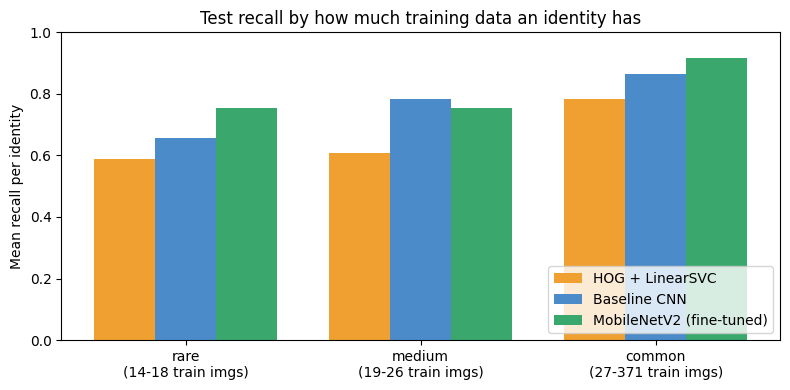

In [49]:
# Do the models differ on identities with little training data?
train_counts = np.bincount(y_train, minlength=n_classes)
lo_cut, hi_cut = np.quantile(train_counts, [1 / 3, 2 / 3])
group_of = np.where(train_counts <= lo_cut, 0, np.where(train_counts <= hi_cut, 1, 2))
group_names = ["rare", "medium", "common"]

recall = {}
for n in model_names:
    _, rec, _, _ = precision_recall_fscore_support(y_test, test_pred[n], labels=np.arange(n_classes), zero_division=0)
    recall[n] = rec

print(f"Identities grouped by number of TRAINING images (three groups):")
for g, gname in enumerate(group_names):
    members = group_of == g
    print(f"  {gname:7s}: {members.sum():2d} identities, {train_counts[members].min():3d} to {train_counts[members].max():3d} training images each")

print(f"\nMean per-identity recall on the test set:")
print(f"{'Model':26s} " + " ".join(f"{g:>8s}" for g in group_names))
for n in model_names:
    print(f"{n:26s} " + " ".join(f"{recall[n][group_of == g].mean():8.1%}" for g in range(3)))
print(f"\nIdentities never recognised on the test set: "
      + ", ".join(f"{n}: {(recall[n] == 0).sum()}" for n in model_names))

model_colors = {"HOG + LinearSVC": "#f0a030", "Baseline CNN": "#4c8bc9", "MobileNetV2 (fine-tuned)": "#3aa76d"}

x = np.arange(3); width = 0.26
fig, ax = plt.subplots(figsize=(8, 4))
for k, n in enumerate(model_names):
    ax.bar(x + (k - 1) * width, [recall[n][group_of == g].mean() for g in range(3)], width,
           label=n, color=model_colors[n])
ax.set_xticks(x); ax.set_xticklabels([f"{g}\n({train_counts[group_of == i].min()}-{train_counts[group_of == i].max()} train imgs)"
                                     for i, g in enumerate(group_names)])
ax.set_ylabel("Mean recall per identity"); ax.set_ylim(0, 1); ax.legend(loc="lower right")
ax.set_title("Test recall by how much training data an identity has")
plt.tight_layout()
plt.show()

Best model on the test set by macro-F1: MobileNetV2 (fine-tuned)

Most frequent confusions (true -> predicted):
  Gloria Macapagal Arroyo  -> Laura Bush               x1
  George W Bush            -> Junichiro Koizumi        x1
  Ricardo Lagos            -> Jean Chretien            x1
  Lleyton Hewitt           -> Jennifer Capriati        x1
  Colin Powell             -> Igor Ivanov              x1
  Colin Powell             -> Tony Blair               x1

Weakest identities (recall, test images):
  Mahmoud Abbas             25%  (4 test images, 20 training images)
  Amelie Mauresmo           33%  (3 test images, 15 training images)
  Carlos Menem              33%  (3 test images, 15 training images)
  Angelina Jolie            33%  (3 test images, 14 training images)
  Tiger Woods               33%  (3 test images, 16 training images)
  Silvio Berlusconi         40%  (5 test images, 23 training images)

60 of 454 test faces misclassified. Showing the 10 most confident mistakes:


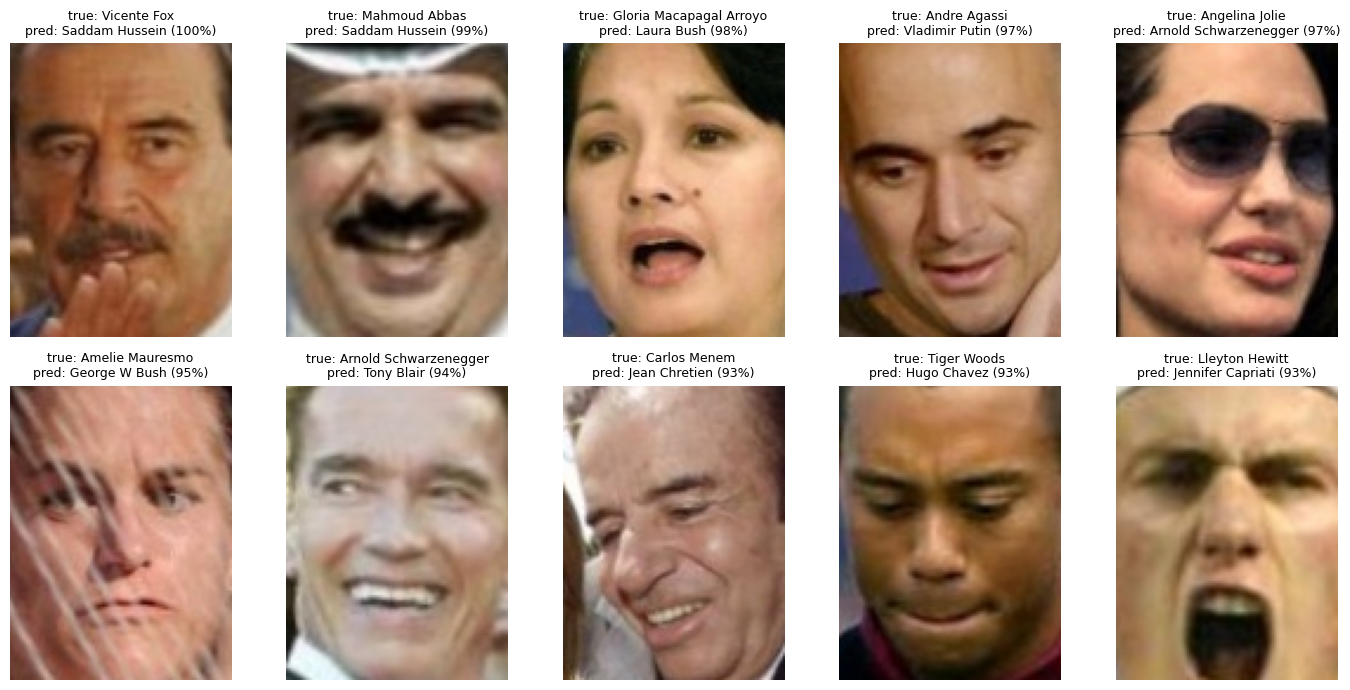

In [50]:
best_name = max(model_names, key=lambda n: test_f1[n])
best_pred = test_pred[best_name]
print(f"Best model on the test set by macro-F1: {best_name}\n")

cm = confusion_matrix(y_test, best_pred, labels=np.arange(n_classes))
np.fill_diagonal(cm, 0)
print("Most frequent confusions (true -> predicted):")
for flat in np.argsort(cm, axis=None)[::-1][:6]:
    t, p = divmod(flat, n_classes)
    print(f"  {class_names[t]:24s} -> {class_names[p]:24s} x{cm[t, p]}")

_, rec_best, _, sup_best = precision_recall_fscore_support(y_test, best_pred, labels=np.arange(n_classes), zero_division=0)
print("\nWeakest identities (recall, test images):")
for i in np.argsort(rec_best)[:6]:
    print(f"  {class_names[i]:24s} {rec_best[i]:4.0%}  ({sup_best[i]} test images, {train_counts[i]} training images)")

# The model's most confident mistakes
wrong = np.where(best_pred != y_test)[0]
has_prob = best_name != "HOG + LinearSVC"
order = wrong[np.argsort(-test_scores[best_name][wrong].max(axis=1))] if has_prob else wrong
shown = order[:10]
print(f"\n{len(wrong)} of {n_test} test faces misclassified. Showing "
      + ("the 10 most confident mistakes:" if has_prob else "the first 10 mistakes:"))

fig, axes = plt.subplots(2, 5, figsize=(14, 7))
for ax, i in zip(axes.ravel(), shown):
    conf = f" ({test_scores[best_name][i].max():.0%})" if has_prob else ""
    ax.imshow(X_test[i])
    ax.set_title(f"true: {class_names[y_test[i]]}\npred: {class_names[best_pred[i]]}{conf}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

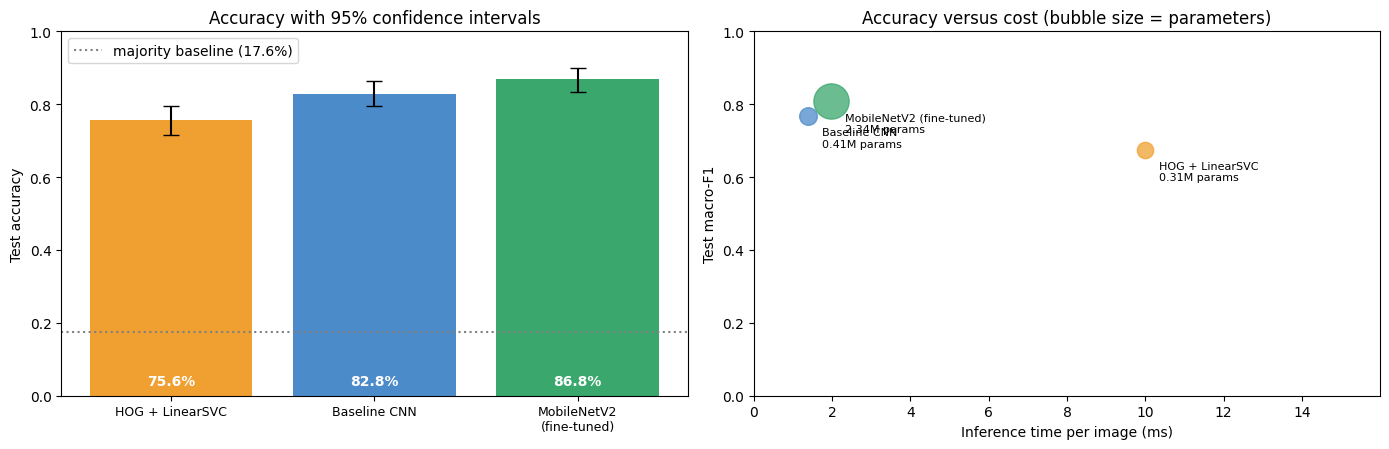

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (a) accuracy with 95% bootstrap intervals
acc_vals = np.array([test_acc[n] for n in model_names])
err = np.array([[test_acc[n] - ci(boot_acc[n])[0], ci(boot_acc[n])[1] - test_acc[n]] for n in model_names]).T
axes[0].bar(range(3), acc_vals, yerr=err, capsize=6, color=[model_colors[n] for n in model_names])
axes[0].axhline(BASELINE_TEST, color="gray", ls=":", label=f"majority baseline ({BASELINE_TEST:.1%})")
axes[0].set_xticks(range(3)); axes[0].set_xticklabels([n.replace(" (", "\n(") for n in model_names], fontsize=9)
for k, v in enumerate(acc_vals): axes[0].text(k, 0.03, f"{v:.1%}", ha="center", color="white", fontweight="bold")
axes[0].set_ylim(0, 1); axes[0].set_ylabel("Test accuracy"); axes[0].legend(loc="upper left")
axes[0].set_title("Accuracy with 95% confidence intervals")

# (b) accuracy vs cost: inference time (x), macro-F1 (y), bubble size = parameters
for n in model_names:
    axes[1].scatter(infer_ms[n], test_f1[n], s=results[n]["params"] / 4000 + 60, color=model_colors[n], alpha=0.75)
    axes[1].annotate(f"{n}\n{results[n]['params'] / 1e6:.2f}M params", (infer_ms[n], test_f1[n]),
                     textcoords="offset points", xytext=(10, -22), fontsize=8)
axes[1].set_xlim(0, max(infer_ms.values()) * 1.6); axes[1].set_xlabel("Inference time per image (ms)")
axes[1].set_ylabel("Test macro-F1"); axes[1].set_ylim(0, 1)
axes[1].set_title("Accuracy versus cost (bubble size = parameters)")
plt.tight_layout()
plt.show()

### Interpretation: final results on the test set

**The headline**

| Model | Test accuracy | Top-5 | Macro-F1 | Val accuracy | Val to test |
|---|---|---|---|---|---|
| Majority class | 17.6% | none | 0.005 | 17.4% | none |
| HOG + LinearSVC | 75.6% | 85.7% | 0.675 | 75.3% | +0.3 |
| Baseline CNN | 82.8% | 94.7% | 0.767 | 84.1% | -1.3 |
| **MobileNetV2 (fine-tuned)** | **86.8%** | **96.7%** | **0.808** | 87.4% | -0.6 |

- The ranking that validation suggested holds on the untouched test set: **fine-tuned MobileNetV2 > baseline CNN > HOG + SVM**, and all three are far above the 17.6% majority baseline.
- The fine-tuned MobileNetV2 misclassifies 60 of the 454 test faces and has the right identity among its top 5 guesses 96.7% of the time.

**Are the differences real?**
- **Both neural models clearly beat HOG.** MobileNetV2 leads by 11.2 points of accuracy (about 51 more faces, 95% interval +7.0 to +15.6) and 0.133 macro-F1 (interval +0.071 to +0.205). The baseline CNN also beats HOG, by 7.3 points (about 33 faces) and 0.093 macro-F1. None of these intervals includes zero.
- **MobileNetV2 versus the baseline CNN is much less clear-cut.** Its accuracy lead is +4.0 points (about 18 faces), but the interval is +0.2 to +7.7, so it only just excludes zero. On macro-F1 the lead is +0.040 with an interval of -0.012 to +0.102, which **cannot be distinguished from zero**. These intervals also don't capture run-to-run training randomness. So the honest reading is that MobileNetV2 is *probably* somewhat better, but this test set cannot prove it.
- The macro-F1 intervals sit below their point estimates. That is a known quirk of bootstrapping with many small classes, so treat those intervals as a rough guide.

**Generalization**
- Test scores are within about 1.3 points of validation for every model, in both directions, which is within sampling noise. So the choices we made on the validation set (early stopping, learning-rate schedules, picking the final weights) did not noticeably overfit it.
- This does *not* rule out the near-duplicate-photo issue. Validation and test were both drawn at random from the same photo pool, so both may be equally flattered by near-twins of training images. The small gap only shows we did not overfit the validation set, not that these numbers would hold on completely new photos.

**Rare versus common identities**

| Mean recall per identity | Rare (14-18 train images) | Medium (19-26) | Common (27-371) |
|---|---|---|---|
| HOG + LinearSVC | 58.7% | 60.6% | 78.2% |
| Baseline CNN | 65.6% | 78.4% | 86.4% |
| MobileNetV2 (fine-tuned) | 75.4% | 75.3% | 91.7% |

- Every model does worse on identities with less training data. MobileNetV2 is the best on rare identities (about 10 points above the baseline CNN and 17 above HOG) and on common ones, and it narrows the rare-to-common gap (16 points, against about 21 for the CNN and 20 for HOG). That fits the idea that pretrained features help most when data is scarce.
- It is *not* a clean win. The baseline CNN scores about 3 points higher on the medium group. Each group has only 18 to 23 identities with 3 to 6 test faces each, so these group averages are noisy.
- **Never recognised on the test set:** 4 identities for HOG, and 0 for both neural models.

**Where the best model fails**
- No confusion pair occurs more than once, so there is **no systematic pattern** among identities. The weakest identities (Mahmoud Abbas, Amelie Mauresmo, Carlos Menem, Angelina Jolie, Tiger Woods) all have between 14 and 20 training images and only 3 to 4 test images, so their scores are noisy.
- The ten most confident mistakes show what goes wrong: **occlusion** (sunglasses, a hand over the face, a striped overlay), **extreme expressions** (wide-open mouths, broad grins) and **head poses turned or tilted down**. Two of them (Vicente Fox and Mahmoud Abbas) were both predicted as Saddam Hussein, another man with a prominent moustache, which suggests the model leans on strong cues such as facial hair when the rest of the face is obscured. That is a hypothesis from two examples, not a finding.
- These mistakes come with **93% to 100% confidence**. The model is often confidently wrong, so its raw confidence is not a reliable warning sign. A real system would need calibration or a "reject / ask for review" threshold.

**Cost**

| | HOG + LinearSVC | Baseline CNN | MobileNetV2 (fine-tuned) |
|---|---|---|---|
| Parameters | 312,542 | 405,790 | 2,337,406 |
| Training time | 36 s (CPU) | 385 s (T4 GPU) | 212 s (T4 GPU) |
| Inference per image | 9.99 ms (CPU) | 1.38 ms (GPU) | 1.98 ms (GPU) |

- MobileNetV2 has about 5.8x the parameters of the baseline CNN and is about 1.4x slower per image, but it trained in roughly 45% less time because it converges in far fewer epochs.
- HOG is the cheapest to train, but it was the slowest per image here, because its feature extraction runs on a CPU. The CPU-versus-GPU difference means the times are only roughly comparable across the two families.
- Whether the extra ~4 points of accuracy justify the larger model depends on the application.

**Caveats**
- This is one training run per model, on one fixed split of a benchmark made of mostly public figures.
- The bootstrap intervals reflect test-set sampling only. They do not include training randomness.
- The small val-to-test gap does not address near-duplicate photos, as noted above.


## 8. Conclusion

**What we built.** A face-recognition pipeline on LFW (62 identities, 3,023 images), taken from raw pixels to a fine-tuned pretrained network, with every model scored under the same conditions.

| Goal | What we did and found |
|---|---|
| Represent faces as tensors | Each face is a `(125, 94, 3)` float tensor, and the dataset a `(3023, 125, 94, 3)` batch. Pixels were already scaled to [0, 1]. |
| Preprocessing and classical filters | Stratified 70/15/15 split. Grayscale, equalization, blur, Sobel and Canny show what handcrafted features capture, and how fixed parameters such as Canny's thresholds fail on some faces. HOG + a linear SVM reached 75.6% test accuracy. |
| Basic CNN | A small 4-block CNN with augmentation and class weights reached 82.8% test accuracy (macro-F1 0.767). |
| Transfer learning | Fine-tuned MobileNetV2 reached the best result, 86.8% (macro-F1 0.808). A frozen backbone alone was not enough (69.1% on validation); fine-tuning gave the big jump. |
| Vision Transformers and self-attention | Explained the idea, cut a face into tokens, computed self-attention by hand and inspected a pretrained ViT's attention. We did not train a ViT, because 2,116 images is far too little for one. |
| Compare accuracy, generalization and cost | Final table and intervals on the untouched test set, plus parameters, training time and inference time. |

**What we conclude**
1. **Learned features beat handcrafted ones.** Both neural models clearly outperformed HOG + SVM on the test set, by 7 to 11 points of accuracy.
2. **Transfer learning is the best option here, but its edge over a well-tuned small CNN is modest.** MobileNetV2 was ahead by 4.0 points of accuracy (barely significant) and 0.040 macro-F1 (not significant), and it helped the rare identities most. It also trained faster than the from-scratch CNN, at the price of a model about 5.8x larger.
3. **Accuracy alone would have misled us.** With 17.5% of images belonging to one person, the majority baseline already scores 17.6%. Macro-F1, per-identity recall and stratified splits were what kept the evaluation honest.
4. **Evaluation noise matters as much as the models.** GPU training isn't exactly repeatable and the test set is small, so several of the differences between models are within noise. Confidence intervals, and ideally repeated runs, are needed to tell them apart.
5. **Data, not architecture, is the limit.** Roughly 34 training images per identity constrains every model, and is why rare identities are always weakest and why a data-hungry ViT was not a sensible choice here.

**Limitations**
- **Possible near-duplicate photos** across the random splits may make all scores optimistic. An event-aware or photo-aware split would be a stricter test.
- **Closed-set task.** The models can only choose among the 62 known people and are often confidently wrong. Real face-recognition systems usually work on verification or open-set identification, with a way to say "unknown".
- **Single runs and a small test set** (3 to 6 test faces for many identities).
- **Dataset scope.** LFW is mostly public figures and is not demographically balanced, so these results say nothing about fairness across groups. Face recognition also raises privacy concerns that a benchmark study like this does not address.

**Next steps if we continued**
- Repeat training over several random seeds and report the spread.
- Use a stricter split that keeps near-duplicate photos together.
- Add calibration or a reject option for uncertain predictions.
- Try a face-specific pretrained embedding model, or fine-tune a small pretrained ViT, and compare it with MobileNetV2 under the same protocol.
